# Music ratings → binary demographic & personality targets

**Predictors:** each participant's liking ratings (1–7) of the **320 clips that every participant heard**
(unchanged from `music_prediction.ipynb`).

**Targets — all turned into two-class problems:**
* **Categorical** (gender, race, area, lyrics vs. instruments, music importance, religion, political view, SES):
  answers are grouped into **two meaningful sides** (e.g. *left* = liberal + progressive + socialist vs. everyone else;
  *upper / upper-middle* vs. *middle class or below*). Answers that belong to neither side are dropped (section 4).
* **Continuous** (age, Big Five): **above vs. below the median** (e.g. *high* vs. *low Openness*).

**Model:** LightGBM (no L1, no row sampling, number of trees set by early stopping). Clips are selected by
recursive feature elimination with a fixed LightGBM setting, then the final model is tuned with Optuna (TPE).
Selection and tuning run inside each training fold of a 5-fold × 3-repeat outer cross-validation.

**Metrics:** balanced accuracy (chance = 0.5) and ROC AUC (chance = 0.5), both on held-out folds only.

In [2]:
%pip install lightgbm optuna

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np, pandas as pd, sqlite3, warnings
import matplotlib.pyplot as plt
import scipy.stats as st
import optuna
import lightgbm as lgb
from lightgbm import LGBMClassifier
from joblib import Parallel, delayed
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, train_test_split
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, roc_curve, confusion_matrix, brier_score_loss
from sklearn.linear_model import LogisticRegressionCV, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

conn = sqlite3.connect("../data/machine2_new_aug.db")
XLS = "../data/Music preference prescreening survey.xlsx"
MIN_RATED = 250          # participant must have rated >= 250 of the 320 core clips
SEED = 42

BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK2, GRID, MUTED = '#52514e', '#e4e3df', '#b9b8b3'


def style(a, axis='both'):
    a.spines[['top', 'right']].set_visible(False)
    a.grid(axis=axis, color=GRID, lw=0.6); a.set_axisbelow(True)


def short(s, n=18):
    s = str(s); return s if len(s) <= n else s[:n - 1] + '…'

c:\Users\zhouz\miniconda3\envs\NSF\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. The 320 core clips
A song is identified by `instanceId`. Only clips presented to every participant exactly once are used
(clip 1000 is presented ~12× per person as an exposure manipulation and is excluded).

In [4]:
n_part = pd.read_sql_query("SELECT COUNT(DISTINCT participantId) n FROM music", conn).n[0]
core = pd.read_sql_query(f'''
    SELECT instanceId FROM music
    GROUP BY instanceId
    HAVING COUNT(DISTINCT participantId) = {n_part} AND COUNT(*) = {n_part}
''', conn).instanceId.tolist()
ratings = pd.read_sql_query(f'''
    SELECT participantId, instanceId, rating FROM music
    WHERE rating IS NOT NULL AND instanceId IN ({",".join(map(str, core))})
''', conn)
X = ratings.pivot(index='participantId', columns='instanceId', values='rating')   # errors on any duplicate
X = X[X.notna().sum(axis=1) >= MIN_RATED]
X = X.fillna(X.mean())                          # the few missing ratings -> clip mean
print(f"{len(core)} core clips; rating matrix {X.shape}")

320 core clips; rating matrix (959, 320)


## 2. Personality (BFI-44)
Most answers are stored as integers, but ~7% are single raw bytes (`b'\x05'` = 5); they are decoded here
(a SQL `CAST` would turn them into 0). `-1` means no response.

In [5]:
bfi = pd.read_sql_query("SELECT participantId, instanceId, agreement_level AS v FROM personality", conn)
bfi['v'] = bfi.v.map(lambda v: int.from_bytes(v, 'little') if isinstance(v, bytes) else v).astype(float)
bfi.loc[bfi.v < 0, 'v'] = np.nan
assert bfi.v.dropna().between(1, 5).all()
bfi = bfi.pivot_table(index='participantId', columns='instanceId', values='v')
REV = [2, 6, 8, 9, 12, 18, 21, 23, 24, 27, 31, 34, 35, 37, 41, 43]
bfi[REV] = 6 - bfi[REV]
SCALES = {'Extraversion': [1, 6, 11, 16, 21, 26, 31, 36],
          'Agreeableness': [2, 7, 12, 17, 22, 27, 32, 37, 42],
          'Conscientiousness': [3, 8, 13, 18, 23, 28, 33, 38, 43],
          'Neuroticism': [4, 9, 14, 19, 24, 29, 34, 39],
          'Openness': [5, 10, 15, 20, 25, 30, 35, 40, 41, 44]}
big5 = pd.DataFrame({k: bfi[v].mean(axis=1) for k, v in SCALES.items()})
big5.reindex(X.index).describe().round(2)

,Extraversion,Agreeableness,Conscientiousness,Neuroticism,Openness
count,959.00,959.00,959.00,959.00,959.00
mean,3.07,3.69,3.36,3.38,3.80
std,0.84,0.63,0.68,0.76,0.59
min,1.00,1.56,1.00,1.12,1.30
25%,2.38,3.22,2.89,2.88,3.40
50%,3.12,3.67,3.33,3.38,3.80
75%,3.62,4.11,3.89,3.88,4.30
max,5.00,5.00,5.00,5.00,5.00


## 3. Prescreen survey, joined on the 4-character code
Codes that appear more than once in the Excel, or 4-character prefixes shared by several DB participants,
are ambiguous and dropped.

In [6]:
raw = pd.read_excel(XLS, header=None).astype(object)
survey = raw.iloc[2:].reset_index(drop=True)
survey['code'] = survey[9].map(lambda s: str(s).strip().lower())
survey = survey[~survey.code.duplicated(keep=False)].set_index('code')

prefix = pd.Series(X.index.str[:4].str.lower(), index=X.index)
prefix = prefix[~prefix.duplicated(keep=False)]
prefix = prefix[prefix.isin(survey.index)]
S = survey.loc[prefix.values].set_index(prefix.index)
print(f"{len(S)} participants matched 1:1 between the DB and the survey")


def txt(col):
    return S[col].map(lambda v: v.strip() if isinstance(v, str) and v.strip() else np.nan)


categorical = {
    'gender':                txt(131).where(txt(131).isin(['Male', 'Female'])),
    'race':                  txt(134),
    'area':                  txt(137).where(txt(137).isin(['Urban', 'Suburban', 'Rural'])),
    'lyrics_vs_instruments': txt(56),
    'music_importance':      txt(55),
    'religion':              txt(111),
    'political_view':        txt(108),
    'SES':                   txt(136).where(txt(136) != 'Prefer not to disclose'),
}
continuous = {'age': pd.to_numeric(S[133], errors='coerce').astype(float),
              **{f'BFI_{k}': big5[k] for k in SCALES}}

797 participants matched 1:1 between the DB and the survey


## 4. Binary targets
* **Categorical → two groups of answers (`SPLITS`).** Ordered answers are cut at a point on the scale, so the two ends
  are never lumped together, and nominal answers are grouped into a coherent contrast:

  | target | positive (1) | negative (0) | dropped |
  |---|---|---|---|
  | gender | Female | Male | (other answers already excluded) |
  | race | Asian | White, Hispanic, Black, Middle Eastern | prefer to self-describe, prefer not to disclose |
  | area | Urban | Suburban, Rural | |
  | lyrics_vs_instruments | Lyrics | Instruments | both equally important |
  | music_importance | big role, music is my life | small role, no role | |
  | religion | Atheism / agnosticism | any religion (incl. "Other") | |
  | political_view | Liberal, Progressive, Socialist | Moderate, Conservative, Libertarian, Alt-Right, I don't care | |
  | SES | Upper, upper middle class | Middle, lower middle, at or below poverty line | |

  (Earlier versions used *most common answer vs. everyone else*, which put e.g. socialists on the conservative side
  and "upper class" with "poverty line".)
* **Continuous → high (1) vs. low (0) around the median.** With tied values at the median (common for age),
  whichever of `> median` or `≥ median` gives the more even split is used.

Both are defined on the analysis sample (participants with ratings). The original answers / scores are kept (`ORIG`)
for the diagnostics in section 9.

In [7]:
# categorical: (positive label, answers), (negative label, answers); answers on neither side are dropped
SPLITS = {
    'gender': (('Female', ['Female']), ('Male', ['Male'])),
    'race': (('Asian', ['Asian']), ('not Asian', ['White', 'Hispanic', 'Black', 'Middle Eastern'])),
    'area': (('Urban', ['Urban']), ('Suburban / rural', ['Suburban', 'Rural'])),
    'lyrics_vs_instruments': (('Lyrics', ['Lyrics']), ('Instruments', ['Instruments'])),
    'music_importance': (('big role / music is my life', ['It plays a big role in my life', 'Music is my life']),
                         ('small / no role', ['It plays a small role in my life', 'It plays no role in my life'])),
    'religion': (('Atheist / agnostic', ['Atheism/Agnosticism']),
                 ('religious', ['Christianity', 'Judaism', 'Islam', 'Hinduism', 'Buddhism', 'Other'])),
    'political_view': (('left (liberal / progressive / socialist)', ['Liberal', 'Progressive', 'Socialist']),
                       ('everyone else', ['Moderate', 'Conservative', 'Libertarian', 'Alt-Right', "I don't care"])),
    'SES': (('upper / upper middle class', ['Upper class', 'Upper middle class']),
            ('middle class or below', ['Middle class', 'Lower middle class', 'At or below poverty line'])),
}

targets, LABELS, RULE, ORIG, KIND, POS_VALUES, DROPPED = {}, {}, {}, {}, {}, {}, {}
for name, ((pos, pos_vals), (neg, neg_vals)) in SPLITS.items():
    y = categorical[name].reindex(X.index).dropna()
    missing = set(pos_vals + neg_vals) - set(y)
    assert not missing, f"{name}: answers not found in the data: {missing}"
    DROPPED[name] = y[~y.isin(pos_vals + neg_vals)].value_counts().to_dict()
    y = y[y.isin(pos_vals + neg_vals)]
    targets[name] = y.isin(pos_vals).astype(int)
    LABELS[name] = (neg, pos)
    RULE[name] = 'grouped answers' + (f" (dropped {sum(DROPPED[name].values())})" if DROPPED[name] else '')
    ORIG[name], KIND[name], POS_VALUES[name] = y, 'categorical', pos_vals
for name, y in continuous.items():
    y = y.reindex(X.index).dropna()
    med = y.median()
    gt, ge = y > med, y >= med
    use_ge = abs(ge.mean() - 0.5) < abs(gt.mean() - 0.5)
    targets[name] = (ge if use_ge else gt).astype(int)
    LABELS[name] = (f"low (< {med:g})" if use_ge else f"low (≤ {med:g})",
                    f"high (≥ {med:g})" if use_ge else f"high (> {med:g})")
    RULE[name] = f"median split at {med:g}"
    ORIG[name], KIND[name] = y, 'continuous'

target_table = pd.DataFrame([dict(target=t, rule=RULE[t], positive_class=LABELS[t][1], negative_class=LABELS[t][0],
                                  n=len(y), n_positive=int(y.sum()), share_positive=y.mean(),
                                  dropped_answers=DROPPED.get(t) or '')
                             for t, y in targets.items()])
target_table.round(3)

,target,rule,positive_class,negative_class,n,n_positive,share_positive,dropped_answers
0,gender,grouped answers,Female,Male,766,527,0.688,
1,race,grouped answers (dropped 53),Asian,not Asian,741,319,0.430,"{'Prefer to self-describe': 42, 'Prefer not to..."
2,area,grouped answers,Urban,Suburban / rural,773,358,0.463,
3,lyrics_vs_instruments,grouped answers (dropped 513),Lyrics,Instruments,276,138,0.500,{'Both are equally important to me': 513}
4,music_importance,grouped answers,big role / music is my life,small / no role,794,641,0.807,
5,religion,grouped answers,Atheist / agnostic,religious,769,317,0.412,
6,political_view,grouped answers,left (liberal / progressive / socialist),everyone else,787,500,0.635,
7,SES,grouped answers,upper / upper middle class,middle class or below,745,371,0.498,
8,age,median split at 19,high (> 19),low (≤ 19),796,372,0.467,
9,BFI_Extraversion,median split at 3.125,high (≥ 3.125),low (< 3.125),959,494,0.515,


## 5. LightGBM: RFE feature selection + Optuna tuning

Inside every outer training fold (5-fold × 3 repeats, stratified):

1. **RFE with static parameters.** Starting from all 320 clips, a fixed LightGBM setting (`RFE_PARAMS`) is fit and
   the least important clips (gain) are dropped along 320 → 256 → … → 5. Every fit early-stops on a validation
   split. An inner 3-fold CV scores each clip count by AUC; with `USE_ONE_SE` the smallest count within one SE of the
   best is kept. RFE is rerun on the whole training fold to get the clip set.
2. **Optuna (TPE) tunes the final model** on those clips: `learning_rate`, `num_leaves`, `min_child_samples`,
   `colsample_bytree`, `reg_lambda` (L2). Each trial is scored by inner 3-fold CV AUC with early stopping; the
   median pruner stops weak trials early. The tree count is the mean early-stopped iteration of the best trial.
3. The final model is refit on the whole training fold and scored on the untouched outer fold.

AUC is used for selection and tuning because it is threshold-free and much less noisy than accuracy at this
sample size. No L1 and no row sampling anywhere (`reg_alpha=0`, `subsample=1`). Classes are **not** reweighted, so on
lopsided targets the models lean toward the larger group (higher plain accuracy, lower balanced accuracy).

In [8]:
LEARNING_RATE = 0.05          # used by RFE (static); Optuna tunes its own learning rate for the final model
MAX_TREES = 5000
EARLY_STOP = 50
RFE_PARAMS = dict(num_leaves=15, min_child_samples=20, colsample_bytree=0.5, reg_lambda=1.0)
FEATURE_COUNTS = [320, 256, 192, 128, 96, 64, 48, 32, 24, 16, 12, 8, 5]
USE_ONE_SE = True
ES_HOLDOUT = 0.15
N_TRIALS = 40
INNER_SPLITS, OUTER_SPLITS, OUTER_REPEATS = 3, 5, 3
N_JOBS = -1                   # parallelize outer folds; Optuna and LightGBM run single-threaded inside
FEATURE_NAMES = X.columns.to_numpy()


def make_model(params, seed, n_estimators=MAX_TREES):
    base = dict(learning_rate=LEARNING_RATE, n_estimators=n_estimators, importance_type='gain',
                subsample=1.0, reg_alpha=0.0,                    # no row sampling, no L1
                class_weight=None, n_jobs=1, verbosity=-1, random_state=seed, force_col_wise=True)   # unweighted
    base.update(params)                                          # tuned values override defaults
    return LGBMClassifier(**base)


def fit_es(params, seed, X_fit, y_fit, X_val, y_val):
    m = make_model(params, seed)
    m.fit(X_fit, y_fit, eval_X=X_val, eval_y=y_val, callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
    return m


def auc_of(model, Xv, yv):
    return roc_auc_score(yv, model.predict_proba(Xv)[:, 1])


def inner_cv(y, seed):
    return list(StratifiedKFold(INNER_SPLITS, shuffle=True, random_state=seed).split(np.zeros(len(y)), y))


def rfe_path(seed, X_fit, y_fit, X_val, y_val, counts):
    """Manual RFE (sklearn's RFE cannot early-stop). Returns {count: (validation AUC, clip indices)}."""
    feats = np.arange(X_fit.shape[1]); out = {}
    for i, k in enumerate(counts):
        m = fit_es(RFE_PARAMS, seed, X_fit[:, feats], y_fit, X_val[:, feats], y_val)
        out[k] = (auc_of(m, X_val[:, feats], y_val), feats.copy())
        if i + 1 < len(counts):
            keep = np.argsort(m.feature_importances_)[::-1][:counts[i + 1]]
            feats = feats[np.sort(keep)]
    return out


def select_clips(Xtr, ytr, seed):
    counts = [k for k in FEATURE_COUNTS if k <= Xtr.shape[1]]
    scores = np.array([[p[k][0] for k in counts]
                       for p in (rfe_path(seed, Xtr[a], ytr[a], Xtr[b], ytr[b], counts)
                                 for a, b in inner_cv(ytr, seed))])
    means, sds = scores.mean(0), scores.std(0)
    best = int(np.argmax(means))
    if USE_ONE_SE:
        eligible = np.flatnonzero(means >= means[best] - sds[best] / np.sqrt(INNER_SPLITS))
        best = int(eligible[np.argmin(np.array(counts)[eligible])])
    k = counts[best]
    a, b = train_test_split(np.arange(len(ytr)), test_size=ES_HOLDOUT, random_state=seed, stratify=ytr)
    feats = rfe_path(seed, Xtr[a], ytr[a], Xtr[b], ytr[b], [c for c in counts if c >= k])[k][1]
    return feats, k, dict(zip(counts, means))


def tune_final(Xs, ytr, seed):
    optuna.logging.set_verbosity(optuna.logging.WARNING)       # also silence parallel workers
    splits = inner_cv(ytr, seed + 1)

    def objective(trial):
        params = dict(
            learning_rate=trial.suggest_float('learning_rate', 0.005, 0.2, log=True),
            num_leaves=trial.suggest_int('num_leaves', 4, 64, log=True),
            min_child_samples=trial.suggest_int('min_child_samples', 5, 100, log=True),
            colsample_bytree=trial.suggest_float('colsample_bytree', 0.3, 1.0),
            reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 30.0, log=True),
        )
        scores, trees = [], []
        for j, (a, b) in enumerate(splits):
            m = fit_es(params, seed, Xs[a], ytr[a], Xs[b], ytr[b])
            scores.append(auc_of(m, Xs[b], ytr[b])); trees.append(m.best_iteration_)
            trial.report(np.mean(scores), j)
            if trial.should_prune():
                raise optuna.TrialPruned()
        trial.set_user_attr('n_trees', int(np.mean(trees)))
        return float(np.mean(scores))

    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=seed, n_startup_trials=10),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=10))
    study.optimize(objective, n_trials=N_TRIALS)
    return study.best_trial


def fit_pipeline(Xtr, ytr, seed):
    feats, k, curve = select_clips(Xtr, ytr, seed)
    best = tune_final(Xtr[:, feats], ytr, seed)
    n_trees = max(best.user_attrs['n_trees'], 1)
    model = make_model(best.params, seed, n_estimators=n_trees).fit(Xtr[:, feats], ytr)
    return dict(model=model, features=feats, count=k, curve=curve, params=best.params,
                n_trees=n_trees, inner_auc=best.value)


def data_for(name):
    y = targets[name]
    return X.loc[y.index].to_numpy(dtype=float), y.to_numpy(dtype=int)


def outer_folds(yn):
    return list(RepeatedStratifiedKFold(n_splits=OUTER_SPLITS, n_repeats=OUTER_REPEATS,
                                        random_state=SEED).split(yn, yn))


def target_seed(name):
    return SEED + 1000 * list(targets).index(name)


def fold_job(name, Xn, yn, fold_id, tr, te):
    fit = fit_pipeline(Xn[tr], yn[tr], target_seed(name) + fold_id)       # outer-training rows only
    proba = fit['model'].predict_proba(Xn[te][:, fit['features']])[:, 1]
    pred = (proba >= 0.5).astype(int)
    mask = np.zeros(Xn.shape[1], bool); mask[fit['features']] = True
    return dict(target=name, repeat=fold_id // OUTER_SPLITS + 1, fold=fold_id % OUTER_SPLITS + 1,
                bal_acc=balanced_accuracy_score(yn[te], pred), auc=roc_auc_score(yn[te], proba),
                n_selected=fit['count'], selected_mask=mask, n_trees=fit['n_trees'], best_params=fit['params'],
                inner_auc=fit['inner_auc'],            # diagnostic only; report the OUTER scores
                test_idx=te, proba=proba, pred=pred)


DATA = {name: data_for(name) for name in targets}
FOLDS = {name: outer_folds(yn) for name, (Xn, yn) in DATA.items()}
jobs = [(name, *DATA[name], i, tr, te) for name in targets for i, (tr, te) in enumerate(FOLDS[name])]
print(f"{len(jobs)} outer folds; each: RFE ({INNER_SPLITS} inner folds x {len(FEATURE_COUNTS)} steps) "
      f"+ {N_TRIALS} Optuna trials x {INNER_SPLITS} inner folds")
fold_results = pd.DataFrame(Parallel(n_jobs=N_JOBS, verbose=5)(delayed(fold_job)(*j) for j in jobs))

results = (fold_results.groupby('target', sort=False)
           .agg(bal_acc=('bal_acc', 'mean'), bal_acc_sd=('bal_acc', 'std'), auc=('auc', 'mean'), auc_sd=('auc', 'std'),
                clips_median=('n_selected', 'median'), clips_min=('n_selected', 'min'), clips_max=('n_selected', 'max'),
                trees_median=('n_trees', 'median'))
           .reset_index()
           .merge(target_table[['target', 'rule', 'positive_class', 'n', 'share_positive']], on='target'))
results.round(3)

210 outer folds; each: RFE (3 inner folds x 13 steps) + 40 Optuna trials x 3 inner folds


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 32 concurrent workers.
[Parallel(n_jobs=-1)]: Done   8 tasks      | elapsed:   14.6s
[Parallel(n_jobs=-1)]: Done  98 tasks      | elapsed:   53.8s
[Parallel(n_jobs=-1)]: Done 190 out of 210 | elapsed:  1.5min remaining:    9.2s
[Parallel(n_jobs=-1)]: Done 210 out of 210 | elapsed:  1.6min finished


,target,bal_acc,bal_acc_sd,auc,auc_sd,clips_median,clips_min,clips_max,trees_median,rule,positive_class,n,share_positive
0,gender,0.700,0.044,0.809,0.041,24.0,12,128,186.0,grouped answers,Female,766,0.688
1,race,0.770,0.033,0.840,0.032,32.0,16,256,189.0,grouped answers (dropped 53),Asian,741,0.430
2,area,0.625,0.033,0.670,0.035,48.0,5,128,137.0,grouped answers,Urban,773,0.463
3,lyrics_vs_instruments,0.648,0.052,0.685,0.052,12.0,5,96,95.0,grouped answers (dropped 513),Lyrics,276,0.500
4,music_importance,0.510,0.014,0.590,0.064,16.0,5,256,83.0,grouped answers,big role / music is my life,794,0.807
5,religion,0.577,0.029,0.613,0.030,32.0,5,96,68.0,grouped answers,Atheist / agnostic,769,0.412
6,political_view,0.654,0.046,0.729,0.052,24.0,8,256,196.0,grouped answers,left (liberal / progressive / socialist),787,0.635
7,SES,0.588,0.031,0.615,0.030,64.0,8,320,170.0,grouped answers,upper / upper middle class,745,0.498
8,age,0.578,0.048,0.618,0.059,48.0,5,192,114.0,median split at 19,high (> 19),796,0.467
9,BFI_Extraversion,0.578,0.025,0.607,0.027,32.0,5,320,105.0,median split at 3.125,high (≥ 3.125),959,0.515


## 6. Results
Chance is 0.5 for both metrics. Error bars are the SD across the 15 outer folds.

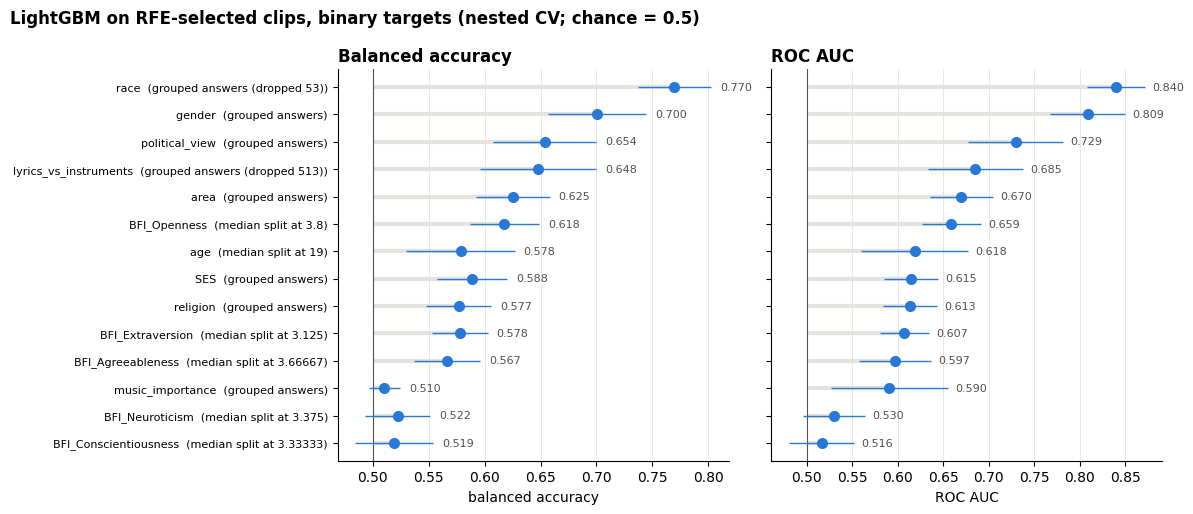

In [9]:
order = results.sort_values('auc').target.tolist()
r = results.set_index('target').loc[order]
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
for a, col, xlabel in [(ax[0], 'bal_acc', 'balanced accuracy'), (ax[1], 'auc', 'ROC AUC')]:
    y = np.arange(len(r))
    a.axvline(0.5, color=INK2, lw=0.8)
    a.hlines(y, 0.5, r[col], color=GRID, lw=3, zorder=1)
    a.errorbar(r[col], y, xerr=r[f'{col}_sd'], fmt='o', color=BLUE, ms=7, elinewidth=1, capsize=0, zorder=3)
    for yi, v, s in zip(y, r[col], r[f'{col}_sd']):
        a.text(v + s + 0.008, yi, f"{v:.3f}", va='center', fontsize=8, color=INK2)
    a.set_xlabel(xlabel); style(a, 'x')
ax[0].set_yticks(range(len(r)))
ax[0].set_yticklabels([f"{t}  ({short(r.positive_class[t], 22)} vs rest)" if r.rule[t].startswith('most')
                       else f"{t}  ({r.rule[t]})" for t in order], fontsize=8)
ax[0].set_title('Balanced accuracy', loc='left', fontweight='bold'); ax[1].set_title('ROC AUC', loc='left', fontweight='bold')
fig.suptitle('LightGBM on RFE-selected clips, binary targets (nested CV; chance = 0.5)', x=0.01, ha='left',
             fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

## 7. Final models: the same pipeline on all participants
RFE (static parameters) picks the clips from all 320, then Optuna tunes the final LightGBM on them.
Each curve shows the inner-CV AUC of the static RFE model at each clip count; the dot marks the count kept.

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 32 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of  14 | elapsed:    5.0s remaining:   30.6s
[Parallel(n_jobs=-1)]: Done   5 out of  14 | elapsed:    7.4s remaining:   13.4s
[Parallel(n_jobs=-1)]: Done   8 out of  14 | elapsed:   11.0s remaining:    8.2s
[Parallel(n_jobs=-1)]: Done  11 out of  14 | elapsed:   13.9s remaining:    3.7s
[Parallel(n_jobs=-1)]: Done  14 out of  14 | elapsed:   26.7s finished


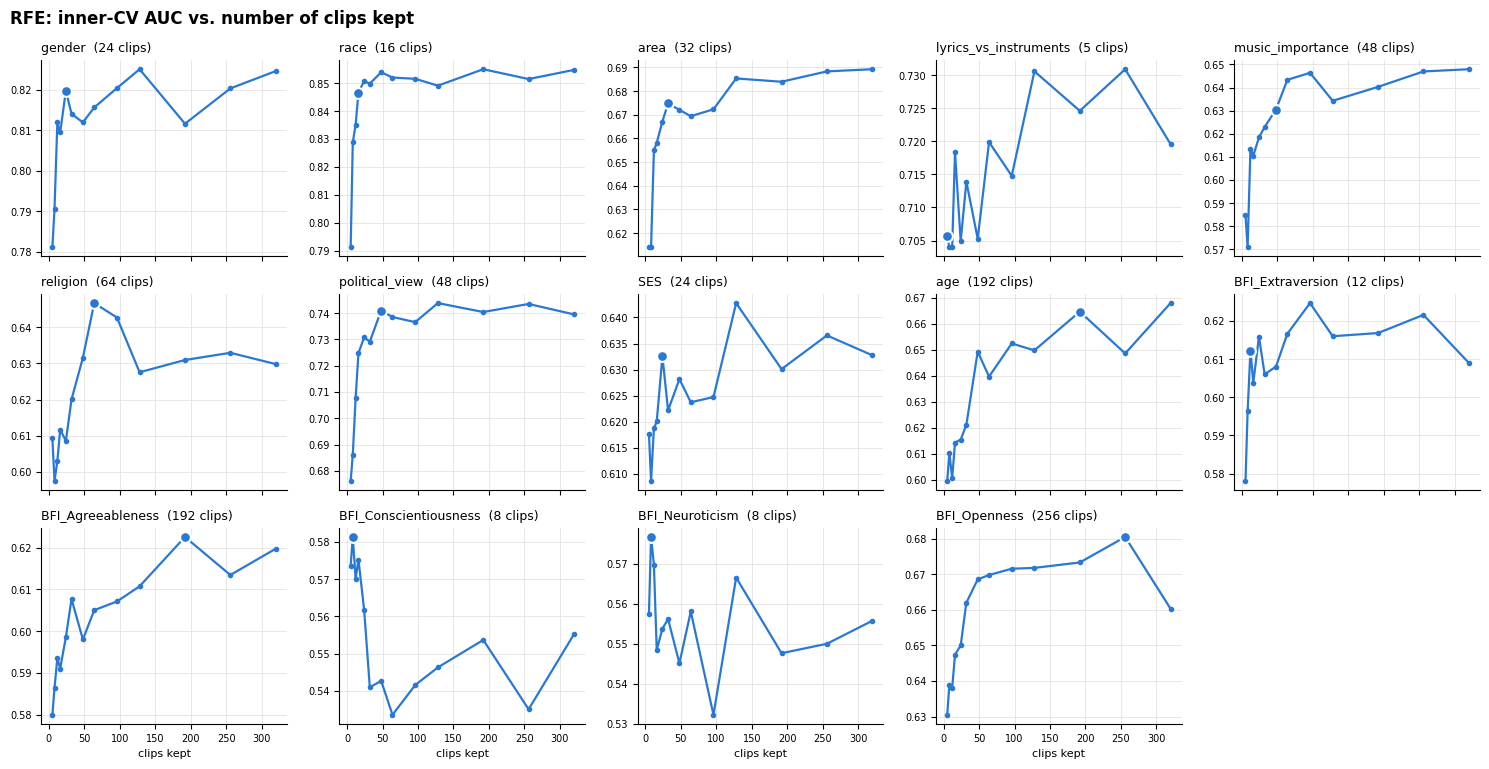

,learning_rate,num_leaves,min_child_samples,colsample_bytree,reg_lambda,n_trees,clips,inner_auc
gender,0.047530,5.0,7.0,0.873277,28.931130,856.0,24.0,0.871
race,0.137141,13.0,48.0,0.443798,0.321988,52.0,16.0,0.881
area,0.011171,58.0,42.0,0.402794,2.520200,717.0,32.0,0.758
lyrics_vs_instruments,0.185723,58.0,28.0,0.358595,0.369911,25.0,5.0,0.797
music_importance,0.153339,17.0,13.0,0.693583,3.469340,27.0,48.0,0.745
religion,0.073565,6.0,64.0,0.852154,0.057632,90.0,64.0,0.706
political_view,0.065636,9.0,16.0,0.935798,0.001392,106.0,48.0,0.808
SES,0.009594,44.0,16.0,0.405175,24.232892,1056.0,24.0,0.699
age,0.021617,11.0,17.0,0.974402,0.184917,233.0,192.0,0.699
BFI_Extraversion,0.126981,56.0,31.0,0.972224,9.315854,26.0,12.0,0.676


In [10]:
def fit_final(name):
    Xn, yn = DATA[name]
    return name, fit_pipeline(Xn, yn, target_seed(name))

final_models = dict(Parallel(n_jobs=N_JOBS, verbose=5)(delayed(fit_final)(t) for t in targets))

names = list(targets); ncol = 5; nrow = int(np.ceil(len(names) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 2.6 * nrow), sharex=True, squeeze=False)
for a, name in zip(axes.flat, names):
    fit = final_models[name]
    counts, means = zip(*sorted(fit['curve'].items()))
    a.plot(counts, means, color=BLUE, lw=1.6, marker='o', ms=3)
    a.scatter([fit['count']], [fit['curve'][fit['count']]], color=BLUE, s=60, edgecolor='white', linewidth=1.5, zorder=3)
    a.set_title(f"{name}  ({fit['count']} clips)", fontsize=9, loc='left'); a.tick_params(labelsize=7); style(a)
for a in list(axes.flat)[len(names):]:
    a.axis('off')
for a in axes[-1]:
    a.set_xlabel('clips kept', fontsize=8)
fig.suptitle('RFE: inner-CV AUC vs. number of clips kept', x=0.01, ha='left', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

pd.DataFrame({t: {**f['params'], 'n_trees': f['n_trees'], 'clips': f['count'], 'inner_auc': round(f['inner_auc'], 3)}
              for t, f in final_models.items()}).T

In [11]:
meta = pd.read_sql_query('''
    SELECT m.MusicId, m.Title, m.Artist, m.Year, g.Genre
    FROM music_meta m LEFT JOIN music_genre g ON m.GenreId = g.GenreId
''', conn).set_index('MusicId')

rows = []
for name, fit in final_models.items():
    Xn, yn = DATA[name]
    for j, v in zip(fit['features'], fit['model'].feature_importances_):
        clip = FEATURE_NAMES[j]
        # direction: do people in the positive class like this clip more (+) or less (-)?
        diff = Xn[yn == 1, j].mean() - Xn[yn == 0, j].mean()
        rows.append(dict(target=name, positive_class=LABELS[name][1], MusicId=clip, importance=v,
                         rating_diff_pos_minus_neg=diff))
selected = pd.DataFrame(rows).join(meta, on='MusicId')
selected['importance_share'] = selected.importance / selected.groupby('target').importance.transform('sum')
selected = selected.sort_values(['target', 'importance'], ascending=[True, False])

for name in targets:
    top = selected[selected.target == name].head(8)
    print(f"\n=== {name}: {LABELS[name][1]} vs {LABELS[name][0]} — {len(selected[selected.target == name])} clips ===")
    print(top[['importance_share', 'rating_diff_pos_minus_neg', 'Title', 'Artist', 'Year', 'Genre']]
          .round(3).to_string(index=False))


=== gender: Female vs Male — 24 clips ===
 importance_share  rating_diff_pos_minus_neg             Title          Artist  Year                       Genre
            0.094                      0.798               "3"  Britney Spears  2009              Pop/Mainstream
            0.079                     -1.105            Tetris Alexey Pajitnov  1984         World/International
            0.077                     -1.097 Overworld (Zelda)      Koji Kondo  1986         World/International
            0.070                      0.815      Bootylicious Destiny's Child  2001         R&B/Soul/Funk/Disco
            0.062                     -0.766  James Bond Theme    Monty Norman  1962         World/International
            0.058                      0.697     Bleeding Love     Leona Lewis  2008              Pop/Mainstream
            0.056                     -0.902          Iron Man   Black Sabbath  1970 Rock/Alternative/Metal/Punk
            0.056                      0.581     Unde

In [12]:
results.round(4).to_csv("../results/music_binary/music_binary_results.csv", index=False)
selected.round(4).to_csv("../results/music_binary/music_binary_selected_clips.csv", index=False)
print("saved music_binary_results.csv and music_binary_selected_clips.csv")

saved music_binary_results.csv and music_binary_selected_clips.csv


## 8. Logistic regression: vanilla, L2, L1, elastic net

Four logistic regressions on **all 320 clips**, evaluated on exactly the same outer folds as LightGBM
(5-fold × 3 repeats), so every comparison is paired:

| variant | penalty | tuned |
|---|---|---|
| `vanilla` | none | nothing (plain maximum likelihood) |
| `L2` | ridge | `C` |
| `L1` | lasso (drops clips by setting their weight to 0) | `C` |
| `elasticnet` | mix of L1 and L2 | `C` and `l1_ratio` (0 = pure L2, 1 = pure L1) |

`C` is the inverse penalty strength (small `C` = strong penalty). Tuning uses Optuna (TPE) with inner 3-fold CV AUC,
inside each outer training fold only. Ratings are standardized inside the training fold, and classes are not
reweighted (as for LightGBM). The vanilla model has 320 free weights for ~600 training people and no penalty, so it
shows what happens without any regularization.

In [13]:
from sklearn.linear_model import LogisticRegression

LOGIT_VARIANTS = ['vanilla', 'L2', 'L1', 'elasticnet']
N_TRIALS_LOGIT = 40
C_RANGE = (1e-4, 10.0)


def make_logit(variant, C=1.0, l1_ratio=0.5):
    kw = dict(class_weight=None, max_iter=5000)                  # unweighted, like LightGBM
    if variant == 'vanilla':
        kw.update(penalty=None, solver='lbfgs')
    elif variant == 'L2':
        kw.update(penalty='l2', solver='lbfgs', C=C)
    elif variant == 'L1':
        kw.update(penalty='l1', solver='liblinear', C=C)
    else:
        kw.update(penalty='elasticnet', solver='saga', C=C, l1_ratio=l1_ratio)
    return make_pipeline(StandardScaler(), LogisticRegression(**kw))


def tune_logit(variant, Xtr, ytr, seed):
    """Optuna (TPE) over C (and l1_ratio for elastic net); inner 3-fold CV AUC. Returns (params, inner AUC)."""
    warnings.filterwarnings('ignore'); optuna.logging.set_verbosity(optuna.logging.WARNING)
    splits = inner_cv(ytr, seed + 2)
    if variant == 'vanilla':                       # nothing to tune; still report its inner-CV AUC
        return {}, float(np.mean([roc_auc_score(ytr[b], make_logit(variant).fit(Xtr[a], ytr[a]).predict_proba(Xtr[b])[:, 1])
                                  for a, b in splits]))

    def objective(trial):
        params = dict(C=trial.suggest_float('C', *C_RANGE, log=True))
        if variant == 'elasticnet':
            params['l1_ratio'] = trial.suggest_float('l1_ratio', 0.05, 0.95)
        scores = []
        for j, (a, b) in enumerate(splits):
            m = make_logit(variant, **params).fit(Xtr[a], ytr[a])
            scores.append(roc_auc_score(ytr[b], m.predict_proba(Xtr[b])[:, 1]))
            trial.report(np.mean(scores), j)
            if trial.should_prune():
                raise optuna.TrialPruned()
        return float(np.mean(scores))

    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=seed, n_startup_trials=10),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=10))
    study.optimize(objective, n_trials=N_TRIALS_LOGIT)
    return study.best_params, study.best_value


def fit_logit(variant, Xtr, ytr, seed):
    params, inner = tune_logit(variant, Xtr, ytr, seed)
    return make_logit(variant, **params).fit(Xtr, ytr), params, inner


def logit_fold_job(name, variant, Xn, yn, fold_id, tr, te):
    m, params, inner = fit_logit(variant, Xn[tr], yn[tr], target_seed(name) + fold_id)
    proba = m.predict_proba(Xn[te])[:, 1]
    coef = m[-1].coef_.ravel()
    return dict(target=name, variant=variant, repeat=fold_id // OUTER_SPLITS + 1, fold=fold_id % OUTER_SPLITS + 1,
                auc=roc_auc_score(yn[te], proba), bal_acc=balanced_accuracy_score(yn[te], (proba >= 0.5).astype(int)),
                n_nonzero=int((np.abs(coef) > 1e-8).sum()), C=params.get('C', np.nan),
                l1_ratio=params.get('l1_ratio', np.nan), inner_auc=inner, test_idx=te, proba=proba)


logit_folds = pd.DataFrame(Parallel(n_jobs=N_JOBS, verbose=2)(
    delayed(logit_fold_job)(name, v, *DATA[name], i, tr, te)
    for name in targets for v in LOGIT_VARIANTS for i, (tr, te) in enumerate(FOLDS[name])))
print(f"{len(logit_folds)} fits ({len(targets)} targets x {len(LOGIT_VARIANTS)} variants x {OUTER_SPLITS * OUTER_REPEATS} folds)")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 32 concurrent workers.
[Parallel(n_jobs=-1)]: Done 146 tasks      | elapsed:   21.9s
[Parallel(n_jobs=-1)]: Done 365 tasks      | elapsed:  3.8min
[Parallel(n_jobs=-1)]: Done 648 tasks      | elapsed:  7.8min
[Parallel(n_jobs=-1)]: Done 840 out of 840 | elapsed: 15.0min finished


840 fits (14 targets x 4 variants x 15 folds)


### 8.1 Results: four logistic regressions vs. LightGBM
`Δ vs LightGBM` is the mean paired difference in held-out AUC; `p` is the Nadeau–Bengio corrected resampled t-test
(plain paired t-tests are too liberal because the training folds overlap). `clips_used` is the median number of
clips with a non-zero weight (always 320 for vanilla and L2).

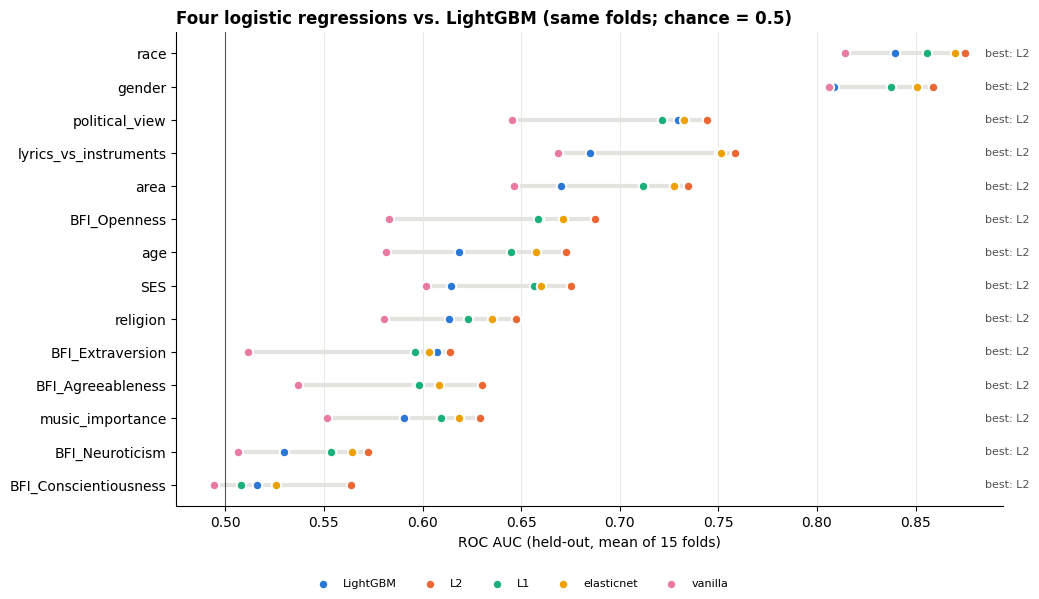

,vanilla,L2,L1,elasticnet,LightGBM,best_model
target,,,,,,
race,0.814,0.875,0.856,0.870,0.840,L2
gender,0.806,0.859,0.838,0.850,0.809,L2
political_view,0.645,0.744,0.721,0.732,0.729,L2
lyrics_vs_instruments,0.669,0.758,0.750,0.751,0.685,L2
area,0.646,0.735,0.712,0.728,0.670,L2
BFI_Openness,0.583,0.687,0.659,0.671,0.659,L2
age,0.582,0.673,0.645,0.658,0.618,L2
SES,0.602,0.676,0.657,0.660,0.615,L2
religion,0.580,0.648,0.623,0.635,0.613,L2


In [14]:
def corrected_t(d, test_frac=1 / OUTER_SPLITS):
    """Nadeau & Bengio (2003) corrected resampled t-test for overlapping CV folds."""
    J = len(d)
    t = d.mean() / np.sqrt((1 / J + test_frac / (1 - test_frac)) * d.var(ddof=1))
    return t, 2 * st.t.sf(abs(t), J - 1)


lg = fold_results[['target', 'repeat', 'fold', 'auc']].rename(columns={'auc': 'lgbm_auc'})
rows = []
for (name, v), d in logit_folds.merge(lg, on=['target', 'repeat', 'fold']).groupby(['target', 'variant'], sort=False):
    diff = (d.auc - d.lgbm_auc).to_numpy(); _, p = corrected_t(diff)
    rows.append(dict(target=name, variant=v, auc=d.auc.mean(), auc_sd=d.auc.std(), bal_acc=d.bal_acc.mean(),
                     inner_auc=d.inner_auc.mean(), optimism=(d.inner_auc - d.auc).mean(),
                     delta_vs_lgbm=diff.mean(), wins_vs_lgbm=f"{(diff > 0).sum()}/{len(diff)}", p_vs_lgbm=p,
                     clips_used=d.n_nonzero.median(), C_median=d.C.median(), l1_ratio_median=d.l1_ratio.median()))
logit_results = pd.DataFrame(rows)

# wide view: AUC per model
auc_wide = (logit_results.pivot(index='target', columns='variant', values='auc')[LOGIT_VARIANTS]
            .join(results.set_index('target')[['auc']].rename(columns={'auc': 'LightGBM'})))
auc_wide['best_model'] = auc_wide.idxmax(axis=1)
auc_wide = auc_wide.loc[order[::-1]]

MODEL_COLORS = {'LightGBM': BLUE, 'L2': ORANGE, 'L1': AQUA, 'elasticnet': '#eda100', 'vanilla': '#e87ba4'}
fig, a = plt.subplots(figsize=(10.5, 6))
y = np.arange(len(auc_wide))[::-1]
vals = auc_wide[list(MODEL_COLORS)]
a.axvline(0.5, color=INK2, lw=0.8)
a.hlines(y, vals.min(1), vals.max(1), color=GRID, lw=3, zorder=1)
for k, (m, col) in enumerate(MODEL_COLORS.items()):
    a.scatter(vals[m], y, s=46, color=col, edgecolor='white', linewidth=1.4, zorder=3 + k, label=m)
for yi, (t, row) in zip(y, auc_wide.iterrows()):
    a.text(vals.to_numpy().max() + 0.01, yi, f"best: {row.best_model}", va='center', fontsize=8, color=INK2)
a.set_yticks(y); a.set_yticklabels(auc_wide.index); a.set_xlabel('ROC AUC (held-out, mean of 15 folds)'); style(a, 'x')
fig.legend(*a.get_legend_handles_labels(), loc='lower center', ncol=5, frameon=False, fontsize=8)
a.set_title('Four logistic regressions vs. LightGBM (same folds; chance = 0.5)', loc='left', fontweight='bold')
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()
auc_wide.round(3)

In [15]:
# full per-variant table
logit_results.sort_values(['target', 'auc'], ascending=[True, False]).round(3)

,target,variant,auc,auc_sd,bal_acc,inner_auc,optimism,delta_vs_lgbm,wins_vs_lgbm,p_vs_lgbm,clips_used,C_median,l1_ratio_median
41,BFI_Agreeableness,L2,0.630,0.025,0.594,0.625,-0.005,0.033,13/15,0.095,320.0,0.001,NaN
43,BFI_Agreeableness,elasticnet,0.608,0.039,0.577,0.612,0.003,0.011,10/15,0.574,55.0,0.012,0.145
42,BFI_Agreeableness,L1,0.598,0.042,0.570,0.603,0.005,0.001,6/15,0.968,29.0,0.052,NaN
40,BFI_Agreeableness,vanilla,0.537,0.040,0.533,0.518,-0.019,-0.061,2/15,0.032,320.0,NaN,NaN
45,BFI_Conscientiousness,L2,0.564,0.045,0.538,0.567,0.003,0.048,13/15,0.119,320.0,0.000,NaN
47,BFI_Conscientiousness,elasticnet,0.526,0.032,0.514,0.549,0.024,0.009,9/15,0.718,42.0,0.021,0.280
46,BFI_Conscientiousness,L1,0.508,0.028,0.504,0.546,0.038,-0.008,7/15,0.708,27.0,0.052,NaN
44,BFI_Conscientiousness,vanilla,0.494,0.045,0.489,0.510,0.016,-0.022,6/15,0.512,320.0,NaN,NaN
37,BFI_Extraversion,L2,0.614,0.027,0.569,0.614,-0.000,0.007,8/15,0.680,320.0,0.000,NaN
39,BFI_Extraversion,elasticnet,0.603,0.029,0.561,0.610,0.007,-0.004,6/15,0.831,22.0,0.013,0.285


### 8.2 Final logistic models on all participants
Each variant is tuned and fit once on everyone. Coefficients are on **standardized** ratings: a coefficient of +0.2
means one SD more liking for that clip raises the log-odds of the positive class (positive group / high score)
by 0.2, holding the other clips fixed. Because the 320 clips are correlated, individual L2 weights are spread thin
and L1 picks one clip out of a correlated group somewhat arbitrarily. Read the lists as "clips that carry the
signal", not as unique causes.

In [16]:
def logit_final(name, variant):
    Xn, yn = DATA[name]
    m, params, inner = fit_logit(variant, Xn, yn, target_seed(name))
    return name, variant, m, params, inner


logit_final_models = {(n, v): (m, p, i) for n, v, m, p, i in Parallel(n_jobs=N_JOBS)(
    delayed(logit_final)(name, v) for name in targets for v in LOGIT_VARIANTS)}

coef_rows = []
for (name, v), (m, params, inner) in logit_final_models.items():
    for clip, c in zip(FEATURE_NAMES, m[-1].coef_.ravel()):
        coef_rows.append(dict(target=name, variant=v, positive_class=LABELS[name][1], MusicId=clip, coef=c))
logit_coefs = pd.DataFrame(coef_rows).join(meta[['Title', 'Artist', 'Year', 'Genre']], on='MusicId')

print(pd.DataFrame({f"{n} | {v}": dict(C=p.get('C', np.nan), l1_ratio=p.get('l1_ratio', np.nan), inner_auc=i,
                                        clips_used=int((np.abs(m[-1].coef_) > 1e-8).sum()))
                    for (n, v), (m, p, i) in logit_final_models.items()}).T.round(4).to_string())

# top clips for the best logistic variant of each target (best = highest held-out AUC in 8.1)
best_variant = logit_results.loc[logit_results.groupby('target').auc.idxmax()].set_index('target').variant
for name in targets:
    v = best_variant[name]
    d = logit_coefs[(logit_coefs.target == name) & (logit_coefs.variant == v) & (logit_coefs.coef.abs() > 1e-8)]
    d = d.sort_values('coef')
    print(f"\n=== {name} — {v}: clips pushing toward '{LABELS[name][1]}' (+) and toward '{LABELS[name][0]}' (−) ===")
    print(pd.concat([d.tail(6).iloc[::-1], d.head(6)])[['coef', 'Title', 'Artist', 'Year', 'Genre']]
          .round(3).to_string(index=False))

                                         C  l1_ratio  inner_auc  clips_used
gender | vanilla                       NaN       NaN     0.8220       320.0
gender | L2                         0.0111       NaN     0.8576       320.0
gender | L1                         0.2324       NaN     0.8336       151.0
gender | elasticnet                 0.1168    0.2754     0.8431       213.0
race | vanilla                         NaN       NaN     0.8340       320.0
race | L2                           0.0107       NaN     0.8810       320.0
race | L1                           0.1992       NaN     0.8696       136.0
race | elasticnet                   0.0188    0.0811     0.8784       197.0
area | vanilla                         NaN       NaN     0.6590       320.0
area | L2                           0.0051       NaN     0.7380       320.0
area | L1                           0.1052       NaN     0.7244        96.0
area | elasticnet                   0.0101    0.0524     0.7397       192.0
lyrics_vs_in

In [17]:
logit_results.round(4).to_csv("../results/music_binary/music_binary_logit_results.csv", index=False)
logit_coefs.round(5).to_csv("../results/music_binary/music_binary_logit_coefficients.csv", index=False)
print("saved music_binary_logit_results.csv and music_binary_logit_coefficients.csv")

saved music_binary_logit_results.csv and music_binary_logit_coefficients.csv


### 8.3 Best model per target
For each target, the model with the highest held-out **accuracy** among LightGBM and the four logistic regressions.

* `accuracy` depends on class balance, so `majority_baseline` (accuracy of always predicting the larger class) is shown
  next to it. `accuracy_over_baseline` is the real gain.
* `balanced_accuracy` and `auc` have chance = 0.5 regardless of balance.
* All scores are means over the 15 outer folds (held-out only). The confusion matrices pool the held-out predictions
  of all repeats and divide the counts by the number of repeats, so each participant is counted once; cells show
  the count and the row percentage (share of that true class).

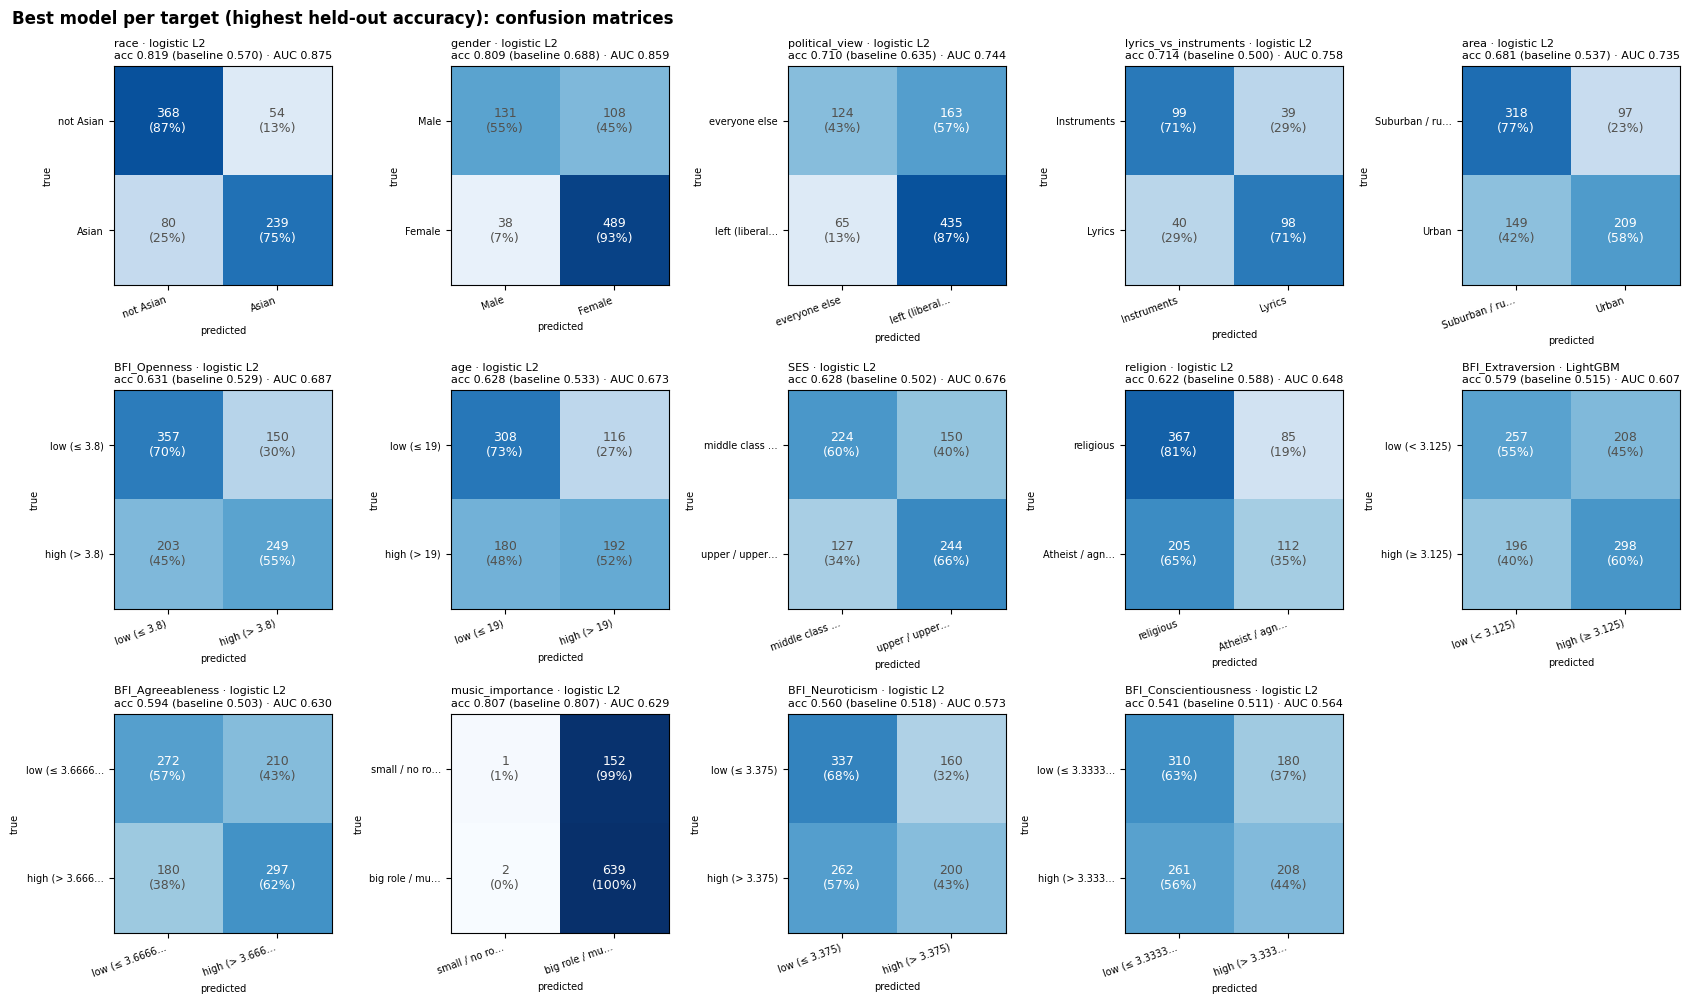

,target,model,accuracy_mean,accuracy_std,majority_baseline,accuracy_over_baseline,balanced_accuracy_mean,auc_mean,auc_std
0,race,logistic L2,0.819,0.027,0.570,0.249,0.810,0.875,0.023
1,gender,logistic L2,0.809,0.032,0.688,0.121,0.738,0.859,0.035
2,political_view,logistic L2,0.710,0.030,0.635,0.075,0.651,0.744,0.041
3,lyrics_vs_instruments,logistic L2,0.714,0.067,0.500,0.214,0.714,0.758,0.062
4,area,logistic L2,0.681,0.027,0.537,0.144,0.674,0.735,0.030
5,BFI_Openness,logistic L2,0.631,0.026,0.529,0.103,0.627,0.687,0.034
6,age,logistic L2,0.628,0.032,0.533,0.096,0.621,0.673,0.029
7,SES,logistic L2,0.628,0.035,0.502,0.126,0.628,0.676,0.029
8,religion,logistic L2,0.622,0.030,0.588,0.035,0.582,0.648,0.029
9,BFI_Extraversion,LightGBM,0.579,0.025,0.515,0.064,0.578,0.607,0.027


In [18]:
from sklearn.metrics import accuracy_score

# held-out predictions of all five models on the same folds
pred_sets = pd.concat([
    fold_results[['target', 'repeat', 'fold', 'test_idx', 'proba']].assign(model='LightGBM'),
    logit_folds[['target', 'repeat', 'fold', 'test_idx', 'proba']].assign(model='logistic ' + logit_folds.variant),
], ignore_index=True)


def fold_metrics(r):
    y = DATA[r['target']][1][r['test_idx']]
    pred = (r['proba'] >= 0.5).astype(int)
    return pd.Series(dict(accuracy=accuracy_score(y, pred), balanced_accuracy=balanced_accuracy_score(y, pred),
                          auc=roc_auc_score(y, r['proba'])))


per_fold = pd.concat([pred_sets[['target', 'model', 'repeat', 'fold']], pred_sets.apply(fold_metrics, axis=1)], axis=1)
model_scores = per_fold.groupby(['target', 'model'], sort=False)[['accuracy', 'balanced_accuracy', 'auc']].agg(['mean', 'std'])
model_scores.columns = [f'{m}_{s}' for m, s in model_scores.columns]
model_scores = model_scores.reset_index()

best = model_scores.loc[model_scores.groupby('target', sort=False).accuracy_mean.idxmax()].copy()
best['majority_baseline'] = best.target.map(lambda t: max(targets[t].mean(), 1 - targets[t].mean()))
best['accuracy_over_baseline'] = best.accuracy_mean - best.majority_baseline
best = best.set_index('target').loc[order[::-1]].reset_index()

ncol = 5; nrow = int(np.ceil(len(best) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 3.4 * nrow), squeeze=False)
for a, r in zip(axes.flat, best.itertuples()):
    s = pred_sets[(pred_sets.target == r.target) & (pred_sets.model == r.model)]
    y_true = np.concatenate([DATA[r.target][1][idx] for idx in s.test_idx])
    y_pred = np.concatenate([(p >= 0.5).astype(int) for p in s.proba])
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1]) / OUTER_REPEATS
    pct = cm / cm.sum(1, keepdims=True)
    a.imshow(pct, cmap='Blues', vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]:.0f}\n({pct[i, j]:.0%})", ha='center', va='center', fontsize=9,
                   color='white' if pct[i, j] > 0.55 else INK2)
    labs = [short(LABELS[r.target][0], 14), short(LABELS[r.target][1], 14)]
    a.set_xticks([0, 1]); a.set_xticklabels(labs, fontsize=7, rotation=20, ha='right')
    a.set_yticks([0, 1]); a.set_yticklabels(labs, fontsize=7)
    a.set_xlabel('predicted', fontsize=7); a.set_ylabel('true', fontsize=7)
    a.set_title(f"{r.target} · {r.model}\nacc {r.accuracy_mean:.3f} (baseline {r.majority_baseline:.3f}) · AUC {r.auc_mean:.3f}",
                fontsize=8, loc='left')
for a in list(axes.flat)[len(best):]:
    a.axis('off')
fig.suptitle('Best model per target (highest held-out accuracy): confusion matrices', x=0.01, ha='left',
             fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

best[['target', 'model', 'accuracy_mean', 'accuracy_std', 'majority_baseline', 'accuracy_over_baseline',
      'balanced_accuracy_mean', 'auc_mean', 'auc_std']].round(3)

In [19]:
# accuracy of every model for every target (held-out means over 15 folds)
acc_wide = model_scores.pivot(index='target', columns='model', values='accuracy_mean').loc[order[::-1]]
acc_wide['majority_baseline'] = [max(targets[t].mean(), 1 - targets[t].mean()) for t in acc_wide.index]
model_scores.to_csv("../results/music_binary/music_binary_all_model_scores.csv", index=False)
best.to_csv("../results/music_binary/music_binary_best_models.csv", index=False)
print("saved music_binary_all_model_scores.csv and music_binary_best_models.csv")
acc_wide.round(3)

saved music_binary_all_model_scores.csv and music_binary_best_models.csv


model,LightGBM,logistic L1,logistic L2,logistic elasticnet,logistic vanilla,majority_baseline
target,,,,,,
race,0.778,0.784,0.819,0.805,0.756,0.570
gender,0.775,0.805,0.809,0.807,0.775,0.688
political_view,0.707,0.695,0.710,0.701,0.639,0.635
lyrics_vs_instruments,0.647,0.686,0.714,0.697,0.614,0.500
area,0.631,0.661,0.681,0.670,0.613,0.537
BFI_Openness,0.620,0.614,0.631,0.626,0.569,0.529
age,0.584,0.607,0.628,0.615,0.575,0.533
SES,0.588,0.613,0.628,0.617,0.573,0.502
religion,0.609,0.596,0.622,0.616,0.570,0.588


## 9. Diagnostics: where does performance break down?

All numbers use the **same outer folds** as section 5 and only held-out predictions.

| § | Question | Look at |
|---|---|---|
| 9.1 | Is LightGBM the bottleneck? Does the binary split throw information away? | LightGBM vs. logistic regression on identical folds; for median splits, a ridge model trained on the **original continuous score** |
| 9.2 | How much signal is in the 320 clips? | per-clip AUC vs. its permutation null; # clips surviving FDR; Big Five reliability |
| 9.3 | Which side of each split fails? | confusion matrices, sensitivity vs. specificity, ROC curves |
| 9.4 | Calibration, threshold, and *who* gets misclassified | reliability curves, Brier skill, best-threshold gap, error rate by distance from the median, error rate by original subgroup |
| 9.5 | Overfitting or instability? | inner vs. outer AUC, fold spread, clip-selection agreement, tuned-setting spread |
| 9.6 | Would more participants help? | learning curves |
| 9.7 | One-table summary | everything above, per target |

In [20]:
OOF = {name: pd.concat([pd.DataFrame({'repeat': r.repeat, 'fold': r.fold, 'row': r.test_idx,
                                      'y': DATA[name][1][r.test_idx], 'proba': r.proba, 'pred': r.pred})
                        for r in d.itertuples()], ignore_index=True)
       for name, d in fold_results.groupby('target', sort=False)}
RES = results.set_index('target')


def bh(p):
    """Benjamini-Hochberg q-values."""
    p = np.asarray(p, float); n = len(p); o = np.argsort(p)
    q = np.empty(n); q[o] = np.minimum.accumulate((p[o] * n / np.arange(1, n + 1))[::-1])[::-1]
    return np.minimum(q, 1)


print(f"held-out predictions for {len(OOF)} targets x {OUTER_REPEATS} repeats")

held-out predictions for 14 targets x 3 repeats


### 9.1 Is LightGBM the bottleneck — and does dichotomizing cost information?
* **logistic** – the Optuna-tuned **L2** logistic regression from section 8 (all 320 clips, same folds).
* **ridge on continuous** (median-split targets only) – ridge regression trained on the *original* score
  (e.g. the Openness scale value), whose predictions are then used to rank people for the high/low label.
  If it beats the binary models, the median split is throwing away information.

Differences use the Nadeau–Bengio corrected t-test (plain paired t-tests are too liberal with overlapping folds).

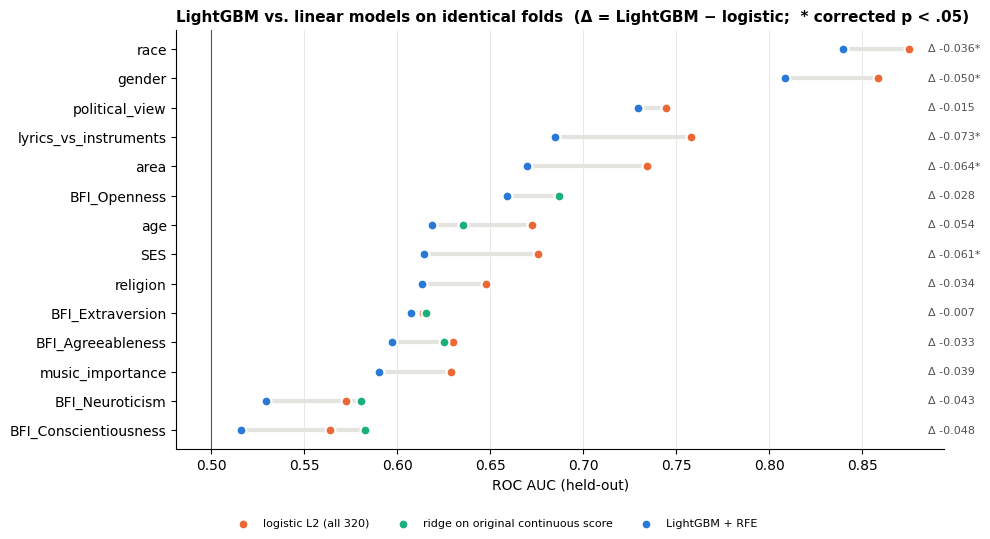

,target,rule,lgbm_auc,logistic_auc,lgbm_minus_logistic_auc,lgbm_wins,p_corrected,lgbm_bal_acc,logistic_bal_acc,ridge_continuous_auc,continuous_minus_logistic_auc,p_corrected_continuous
0,gender,grouped answers,0.809,0.859,-0.050,0/15,0.031,0.700,0.738,NaN,NaN,NaN
1,race,grouped answers (dropped 53),0.840,0.875,-0.036,1/15,0.027,0.770,0.810,NaN,NaN,NaN
2,area,grouped answers,0.670,0.735,-0.064,0/15,0.007,0.625,0.674,NaN,NaN,NaN
3,lyrics_vs_instruments,grouped answers (dropped 513),0.685,0.758,-0.073,1/15,0.017,0.648,0.714,NaN,NaN,NaN
4,music_importance,grouped answers,0.590,0.629,-0.039,4/15,0.329,0.510,0.503,NaN,NaN,NaN
5,religion,grouped answers,0.613,0.648,-0.034,2/15,0.120,0.577,0.582,NaN,NaN,NaN
6,political_view,grouped answers,0.729,0.744,-0.015,3/15,0.448,0.654,0.651,NaN,NaN,NaN
7,SES,grouped answers,0.615,0.676,-0.061,0/15,0.002,0.588,0.628,NaN,NaN,NaN
8,age,median split at 19,0.618,0.673,-0.054,1/15,0.110,0.578,0.621,0.635,-0.037,0.081
9,BFI_Extraversion,median split at 3.125,0.607,0.614,-0.007,7/15,0.680,0.578,0.569,0.616,0.002,0.876


In [21]:
def ridge_job(name, Xn, yn, yc, fold_id, tr, te):
    """Median-split targets: ridge on the ORIGINAL continuous score, used to rank people for the binary label."""
    warnings.filterwarnings('ignore')
    rr = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 5, 25))).fit(Xn[tr], yc[tr])
    return dict(target=name, repeat=fold_id // OUTER_SPLITS + 1, fold=fold_id % OUTER_SPLITS + 1,
                ridge_continuous_auc=roc_auc_score(yn[te], rr.predict(Xn[te])))


ridge = pd.DataFrame(Parallel(n_jobs=N_JOBS)(
    delayed(ridge_job)(name, *DATA[name], ORIG[name].to_numpy(float), i, tr, te)
    for name in targets if KIND[name] == 'continuous' for i, (tr, te) in enumerate(FOLDS[name])))
l2 = (logit_folds[logit_folds.variant == 'L2'][['target', 'repeat', 'fold', 'auc', 'bal_acc']]
      .rename(columns={'auc': 'logistic_auc', 'bal_acc': 'logistic_bal_acc'}))
paired = (fold_results[['target', 'repeat', 'fold', 'auc', 'bal_acc']]
          .merge(l2, on=['target', 'repeat', 'fold'])
          .merge(ridge, on=['target', 'repeat', 'fold'], how='left'))

rows = []
for name, d in paired.groupby('target', sort=False):
    diff = (d.auc - d.logistic_auc).to_numpy(); t, p = corrected_t(diff)
    row = dict(target=name, rule=RULE[name], lgbm_auc=d.auc.mean(), logistic_auc=d.logistic_auc.mean(),
               lgbm_minus_logistic_auc=diff.mean(), lgbm_wins=f"{(diff > 0).sum()}/{len(diff)}", p_corrected=p,
               lgbm_bal_acc=d.bal_acc.mean(), logistic_bal_acc=d.logistic_bal_acc.mean())
    if d.ridge_continuous_auc.notna().all():
        diff2 = (d.ridge_continuous_auc - d.logistic_auc).to_numpy(); _, p2 = corrected_t(diff2)
        row.update(ridge_continuous_auc=d.ridge_continuous_auc.mean(), continuous_minus_logistic_auc=diff2.mean(),
                   p_corrected_continuous=p2)
    rows.append(row)
baseline = pd.DataFrame(rows)

b = baseline.set_index('target').loc[order]
fig, a = plt.subplots(figsize=(10, 5.4))
y = np.arange(len(b))
cols = [c for c in ['lgbm_auc', 'logistic_auc', 'ridge_continuous_auc'] if c in b]
a.axvline(0.5, color=INK2, lw=0.8)
a.hlines(y, b[cols].min(1), b[cols].max(1), color=GRID, lw=3, zorder=1)
a.scatter(b.logistic_auc, y, s=50, color=ORANGE, edgecolor='white', linewidth=1.5, zorder=3, label='logistic L2 (all 320)')
if 'ridge_continuous_auc' in b:
    a.scatter(b.ridge_continuous_auc, y, s=50, color=AQUA, edgecolor='white', linewidth=1.5, zorder=3,
              label='ridge on original continuous score')
a.scatter(b.lgbm_auc, y, s=50, color=BLUE, edgecolor='white', linewidth=1.5, zorder=4, label='LightGBM + RFE')
xmax = np.nanmax(b[cols].to_numpy())
for yi, (t, rr) in zip(y, b.iterrows()):
    a.text(xmax + 0.01, yi, f"Δ {rr.lgbm_minus_logistic_auc:+.3f}{'*' if rr.p_corrected < 0.05 else ''}",
           va='center', fontsize=8, color=INK2)
a.set_yticks(y); a.set_yticklabels(order); a.set_xlabel('ROC AUC (held-out)'); style(a, 'x')
fig.legend(*a.get_legend_handles_labels(), loc='lower center', ncol=3, frameon=False, fontsize=8)
a.set_title('LightGBM vs. linear models on identical folds  (Δ = LightGBM − logistic;  * corrected p < .05)',
            loc='left', fontweight='bold', fontsize=11)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()
baseline.round(3)

### 9.2 How much signal is in the clips?
Descriptive, on all participants (not used by any model). For each clip, its univariate AUC for the binary
label (Mann–Whitney). `best_clip_auc_dev` = the strongest clip's |AUC − 0.5|; `null_best_dev` = the same after
shuffling the label (mean of 50 shuffles). `clips_q05` counts clips surviving Benjamini–Hochberg FDR (≈ 0 by
chance). Many weak-but-real clips and no strong one means the signal is spread thinly across the collection.

For the Big Five, Cronbach's α bounds predictability: the observed score is only partly "true score".

In [22]:
def cronbach(items):
    d = items.dropna(); k = d.shape[1]
    return k / (k - 1) * (1 - d.var(ddof=1).sum() / d.sum(axis=1).var(ddof=1))


def clip_auc(Xn, y):
    U, p = st.mannwhitneyu(Xn[y == 1], Xn[y == 0], axis=0)
    return U / ((y == 1).sum() * (y == 0).sum()), p


def univariate(name, n_null=50):
    Xn, yn = DATA[name]; rng = np.random.default_rng(SEED)
    auc, p = clip_auc(Xn, yn)
    dev = np.abs(auc - 0.5)
    null_best = np.mean([np.abs(clip_auc(Xn, rng.permutation(yn))[0] - 0.5).max() for _ in range(n_null)])
    top = np.argsort(dev)[::-1][:3]
    return dict(target=name, best_clip_auc_dev=dev.max(), null_best_dev=null_best, best_over_null=dev.max() / null_best,
                clips_q05=int((bh(p) < 0.05).sum()), clips_p05=int((p < 0.05).sum()),
                top3=', '.join(f"{short(meta.Title.get(FEATURE_NAMES[i], FEATURE_NAMES[i]), 20)} ({auc[i]:.2f})"
                               for i in top))


signal = pd.DataFrame([univariate(t) for t in targets])
alpha = {f'BFI_{s}': cronbach(bfi.loc[bfi.index.intersection(X.index), it]) for s, it in SCALES.items()}
signal['reliability_alpha'] = signal.target.map(alpha)
signal.round(4)

,target,best_clip_auc_dev,null_best_dev,best_over_null,clips_q05,clips_p05,top3,reliability_alpha
0,gender,0.1803,0.0644,2.8007,185,192,"Overworld (Zelda) (0.32), Tetris (0.33), Bleed...",NaN
1,race,0.2270,0.0609,3.7276,202,212,"Hypnotize (0.27), Get Busy (0.28), Bootyliciou...",NaN
2,area,0.1189,0.0597,1.9917,88,132,"All The Small Things (0.38), I Wanna Hold Your...",NaN
3,lyrics_vs_instruments,0.2030,0.1006,2.0180,160,177,"Perfect (0.70), Stay With Me (0.70), Song With...",NaN
4,music_importance,0.1313,0.0754,1.7415,86,120,"Good Life (0.63), Give It To Me (0.62), One Da...",NaN
5,religion,0.1211,0.0589,2.0574,124,148,"Love in This Club (0.38), Get Busy (0.40), Liv...",NaN
6,political_view,0.1515,0.0616,2.4611,149,172,"Bootylicious (0.65), Texas Tornado (0.36), Hyp...",NaN
7,SES,0.1137,0.0595,1.9117,33,81,"Foolish (0.39), Blowin' in the Wind (0.59), Ro...",NaN
8,age,0.1021,0.0588,1.7359,66,110,"Just the Way You Are (0.40), That's What I Lik...",NaN
9,BFI_Extraversion,0.1111,0.0535,2.0768,159,183,"One Dance (0.61), Despacito (0.60), Gonna Make...",0.8473


### 9.3 Which side of each split fails?
Confusion matrices pool the held-out predictions of all repeats and are **row-normalized** (row = true class).
**Sensitivity** = recall of the positive class (positive group / high); **specificity** = recall of the negative class.
Balanced accuracy is their mean. A model that leans to one side shows a large gap between the two, which a
different probability threshold could fix (see 8.4); two low values mean weak signal.

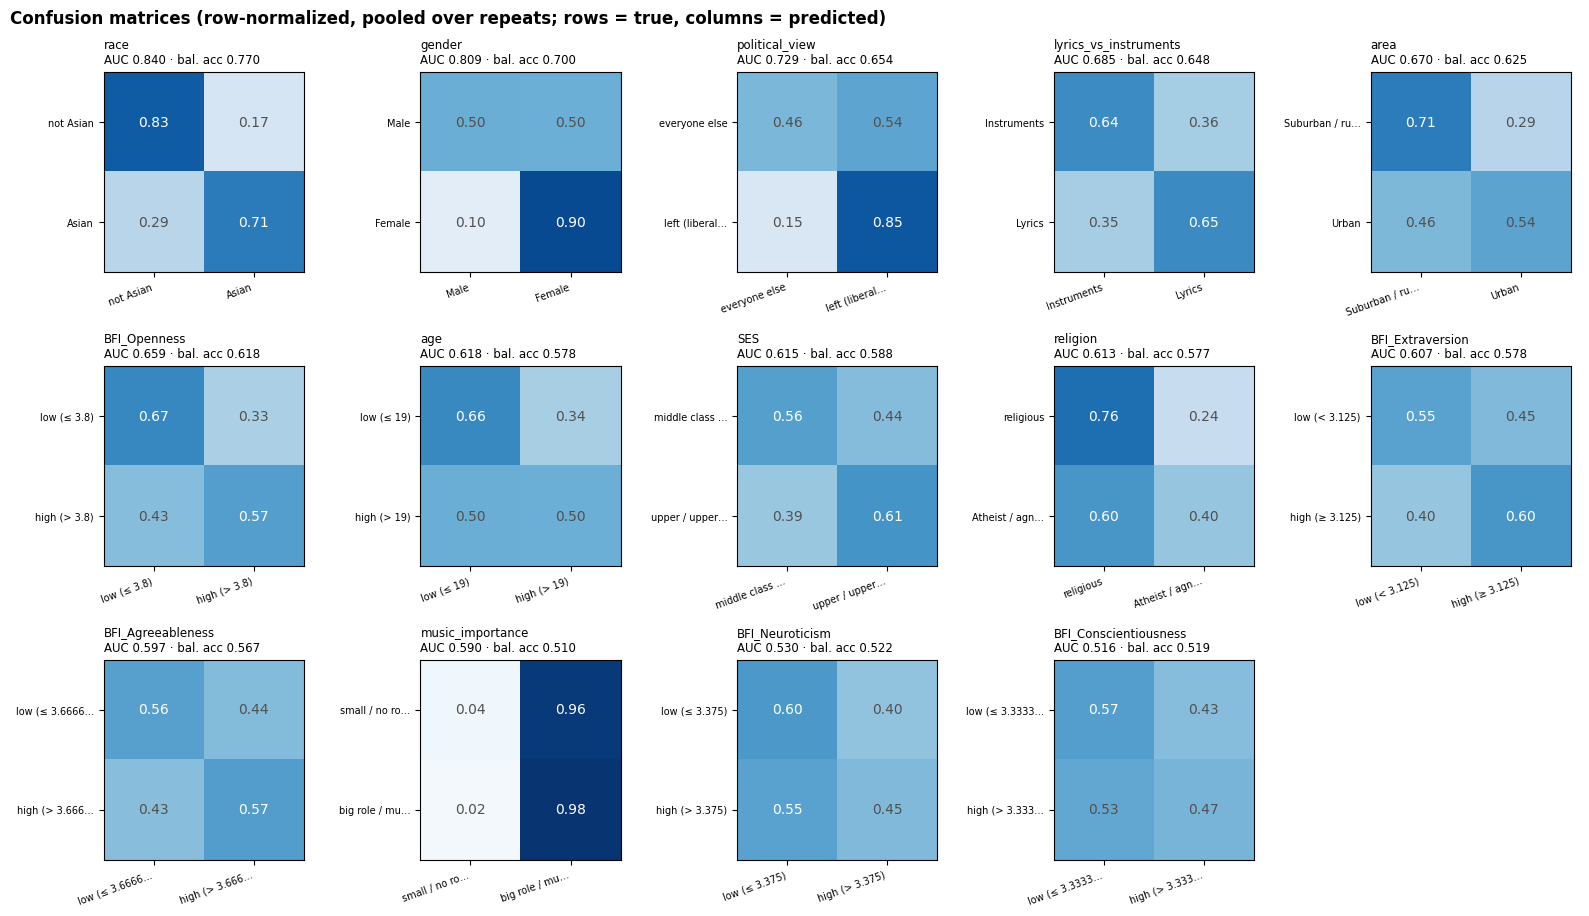

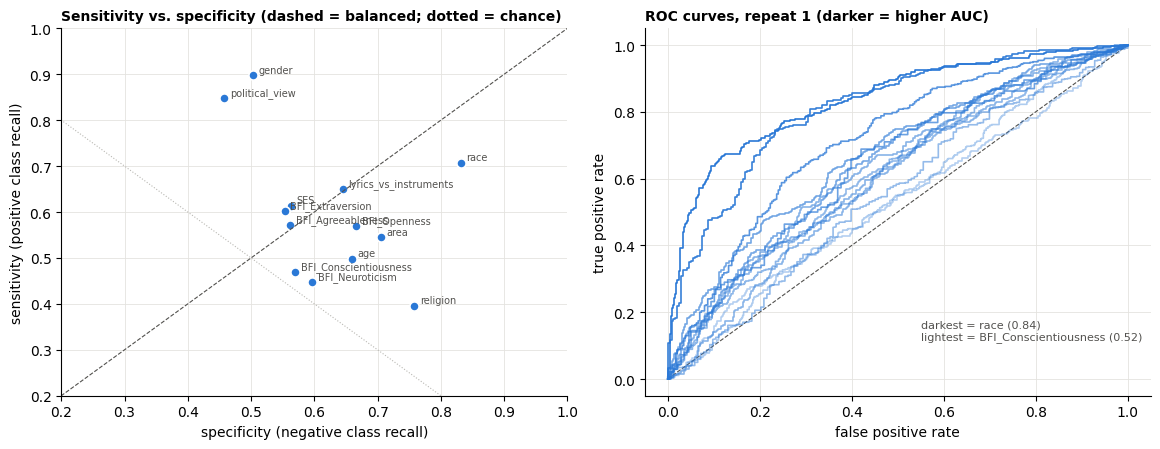

,target,n_pos,n_neg,sensitivity,specificity,precision_pos,precision_neg,predicted_pos_share,true_pos_share,sens_minus_spec
0,race,319,422,0.707,0.832,0.761,0.790,0.400,0.430,-0.124
1,gender,527,239,0.898,0.503,0.799,0.690,0.772,0.688,0.394
2,political_view,500,287,0.849,0.458,0.732,0.635,0.737,0.635,0.392
3,lyrics_vs_instruments,138,138,0.650,0.645,0.647,0.648,0.502,0.500,0.005
4,area,358,415,0.545,0.705,0.614,0.642,0.411,0.463,-0.161
5,BFI_Openness,452,507,0.569,0.666,0.603,0.634,0.445,0.471,-0.097
6,age,372,424,0.498,0.659,0.562,0.599,0.415,0.467,-0.161
7,SES,371,374,0.614,0.563,0.582,0.595,0.525,0.498,0.050
8,religion,317,452,0.395,0.758,0.534,0.641,0.305,0.412,-0.363
9,BFI_Extraversion,494,465,0.603,0.553,0.589,0.567,0.527,0.515,0.049


In [23]:
per_target = []
ncol = 5; nrow = int(np.ceil(len(targets) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 3.1 * nrow), squeeze=False)
for a, name in zip(axes.flat, order[::-1]):
    o = OOF[name]
    cm = confusion_matrix(o.y, o.pred, labels=[0, 1]); cmn = cm / cm.sum(1, keepdims=True)
    a.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cmn[i, j]:.2f}", ha='center', va='center', fontsize=10,
                   color='white' if cmn[i, j] > 0.55 else INK2)
    labs = [short(LABELS[name][0], 14), short(LABELS[name][1], 14)]
    a.set_xticks([0, 1]); a.set_xticklabels(labs, fontsize=7, rotation=20, ha='right')
    a.set_yticks([0, 1]); a.set_yticklabels(labs, fontsize=7)
    a.set_title(f"{name}\nAUC {RES.auc[name]:.3f} · bal. acc {RES.bal_acc[name]:.3f}", fontsize=8.5, loc='left')
    tn, fp, fn, tp = cm.ravel()
    per_target.append(dict(target=name, n_pos=int(o.y.sum() / OUTER_REPEATS), n_neg=int((1 - o.y).sum() / OUTER_REPEATS),
                           sensitivity=tp / (tp + fn), specificity=tn / (tn + fp),
                           precision_pos=tp / (tp + fp) if tp + fp else np.nan,
                           precision_neg=tn / (tn + fn) if tn + fn else np.nan,
                           predicted_pos_share=(o.pred == 1).mean(), true_pos_share=o.y.mean()))
for a in list(axes.flat)[len(targets):]:
    a.axis('off')
fig.suptitle('Confusion matrices (row-normalized, pooled over repeats; rows = true, columns = predicted)',
             x=0.01, ha='left', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()
per_target = pd.DataFrame(per_target)
per_target['sens_minus_spec'] = per_target.sensitivity - per_target.specificity

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
a = ax[0]
a.plot([0, 1], [0, 1], '--', color=INK2, lw=0.8); a.plot([0, 1], [1, 0], ':', color=MUTED, lw=0.8)
a.scatter(per_target.specificity, per_target.sensitivity, s=44, color=BLUE, edgecolor='white', linewidth=1.2)
for rr in per_target.itertuples():
    a.annotate(rr.target, (rr.specificity, rr.sensitivity), fontsize=7, color=INK2, xytext=(4, 2), textcoords='offset points')
a.set_xlabel('specificity (negative class recall)'); a.set_ylabel('sensitivity (positive class recall)')
a.set_xlim(0.2, 1); a.set_ylim(0.2, 1)
a.set_title('Sensitivity vs. specificity (dashed = balanced; dotted = chance)', loc='left', fontweight='bold', fontsize=10)
style(a)
a = ax[1]
a.plot([0, 1], [0, 1], '--', color=INK2, lw=0.8)
for name in order[::-1]:
    o = OOF[name][OOF[name].repeat == 1]
    fpr, tpr, _ = roc_curve(o.y, o.proba)
    a.plot(fpr, tpr, lw=1.2, color=BLUE, alpha=0.35 + 0.65 * (RES.auc[name] - RES.auc.min()) / (RES.auc.max() - RES.auc.min() + 1e-9))
best_t, worst_t = order[-1], order[0]
a.text(0.55, 0.12, f"darkest = {best_t} ({RES.auc[best_t]:.2f})\nlightest = {worst_t} ({RES.auc[worst_t]:.2f})",
       fontsize=8, color=INK2)
a.set_xlabel('false positive rate'); a.set_ylabel('true positive rate')
a.set_title('ROC curves, repeat 1 (darker = higher AUC)', loc='left', fontweight='bold', fontsize=10); style(a)
plt.tight_layout(); plt.show()
per_target.round(3)

### 9.4 Calibration, threshold, and who gets misclassified
**Calibration.** Held-out predicted probabilities are binned and compared with the observed share of positives.
Classes are not reweighted, so the probabilities are meant to match the observed shares; the Brier skill score (1 − Brier / Brier of always predicting the base rate) says whether the probabilities beat
that trivial forecast at all.

**Threshold.** `bal_acc_best_threshold` is balanced accuracy at the best cut-off chosen on the held-out predictions.
That is optimistic (the threshold is fit on the scored data), so read it as an upper bound: a big gap over
the 0.5 threshold means the ranking is fine but the decision point is off.

**Who is misclassified.** For median splits: error rate by decile of the *original* score. People right at the
median are near-coin-flips by construction; if the model is also near chance in the outer deciles, the signal
itself is weak. `extreme_auc` is the AUC restricted to the bottom vs. top quarter of the original score.
For categorical splits: how often each **original** answer is predicted as the positive group, which shows
which answers inside each group the model gets right (e.g. whether socialists are classified like liberals).

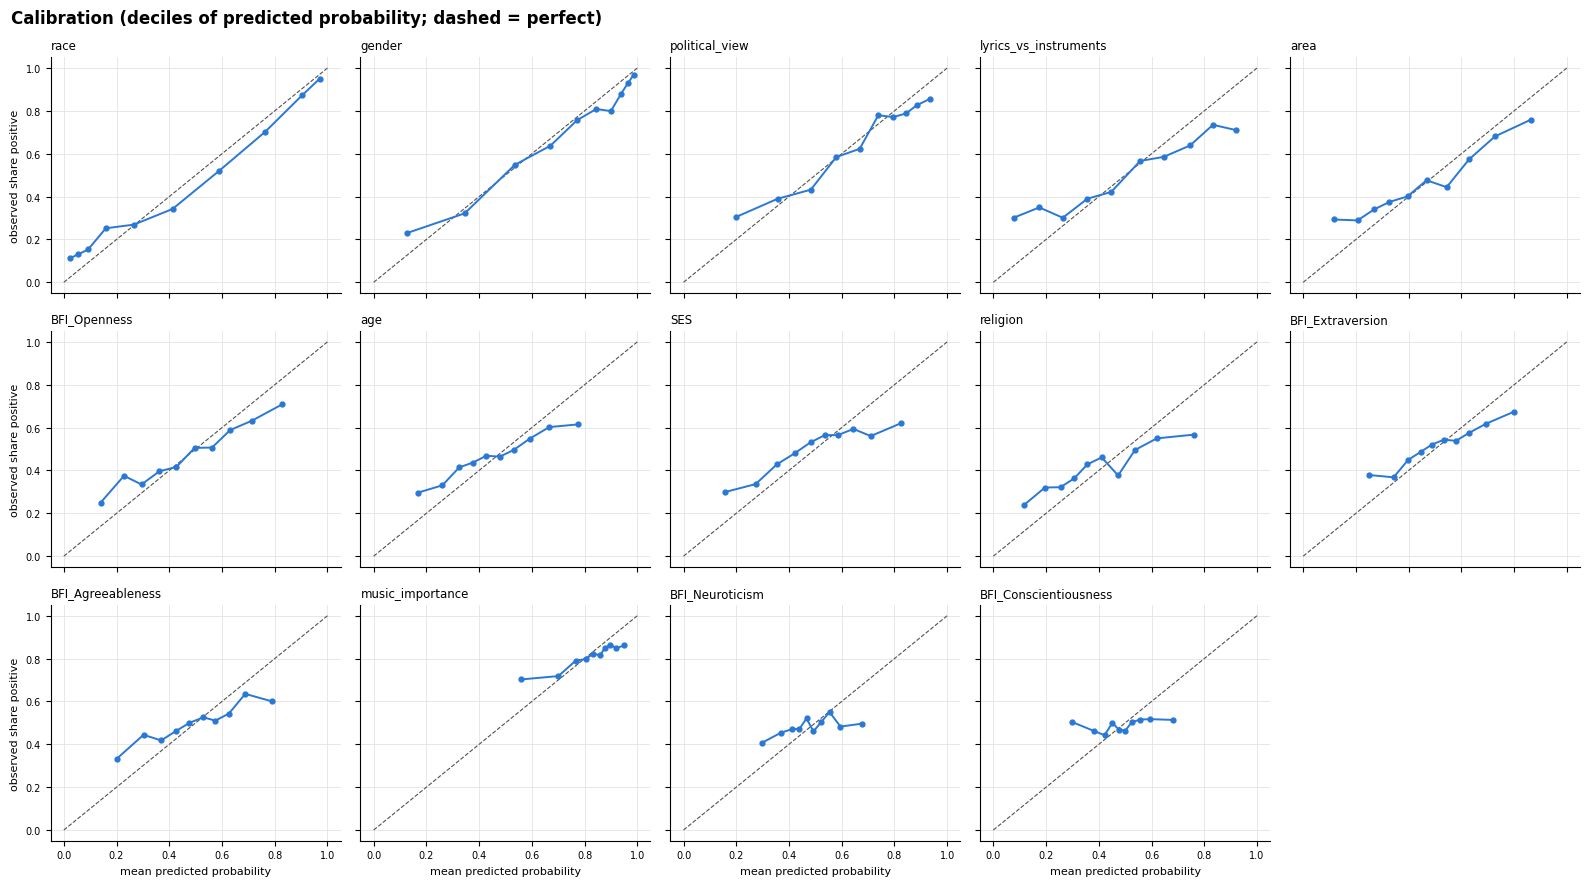

,target,brier,brier_base_rate,brier_skill,bal_acc_at_0_5,bal_acc_best_threshold,best_threshold,threshold_gain
0,race,0.160,0.245,0.348,0.770,0.770,0.518,0.001
1,gender,0.160,0.215,0.255,0.701,0.736,0.725,0.036
2,political_view,0.199,0.232,0.141,0.653,0.686,0.669,0.033
3,lyrics_vs_instruments,0.241,0.250,0.038,0.647,0.655,0.488,0.007
4,area,0.233,0.249,0.062,0.625,0.629,0.567,0.004
5,BFI_Openness,0.237,0.249,0.048,0.618,0.620,0.467,0.002
6,age,0.247,0.249,0.009,0.579,0.583,0.423,0.005
7,SES,0.249,0.250,0.002,0.588,0.593,0.445,0.005
8,religion,0.242,0.242,0.001,0.577,0.586,0.372,0.009
9,BFI_Extraversion,0.245,0.250,0.017,0.578,0.583,0.441,0.005


In [24]:
calib_rows = []
ncol = 5; nrow = int(np.ceil(len(targets) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 3.0 * nrow), squeeze=False, sharex=True, sharey=True)
for a, name in zip(axes.flat, order[::-1]):
    o = OOF[name]
    bins = pd.qcut(o.proba.rank(method='first'), 10, labels=False)
    cal = o.groupby(bins).agg(p=('proba', 'mean'), obs=('y', 'mean'))
    a.plot([0, 1], [0, 1], '--', color=INK2, lw=0.8)
    a.plot(cal.p, cal.obs, '-o', color=BLUE, ms=3.5, lw=1.4)
    a.set_title(name, fontsize=8.5, loc='left'); a.tick_params(labelsize=7); style(a)
    brier = brier_score_loss(o.y, o.proba); brier0 = brier_score_loss(o.y, np.full(len(o), o.y.mean()))
    thr = np.unique(np.quantile(o.proba, np.linspace(0.02, 0.98, 97)))
    ba = [balanced_accuracy_score(o.y, (o.proba >= t).astype(int)) for t in thr]
    calib_rows.append(dict(target=name, brier=brier, brier_base_rate=brier0, brier_skill=1 - brier / brier0,
                           bal_acc_at_0_5=balanced_accuracy_score(o.y, o.pred), bal_acc_best_threshold=max(ba),
                           best_threshold=thr[int(np.argmax(ba))]))
for a in list(axes.flat)[len(targets):]:
    a.axis('off')
for a in axes[:, 0]:
    a.set_ylabel('observed share positive', fontsize=8)
for a in axes[-1]:
    a.set_xlabel('mean predicted probability', fontsize=8)
fig.suptitle('Calibration (deciles of predicted probability; dashed = perfect)', x=0.01, ha='left', fontsize=12,
             fontweight='bold')
plt.tight_layout(); plt.show()
calib = pd.DataFrame(calib_rows)
calib['threshold_gain'] = calib.bal_acc_best_threshold - calib.bal_acc_at_0_5
calib.round(3)

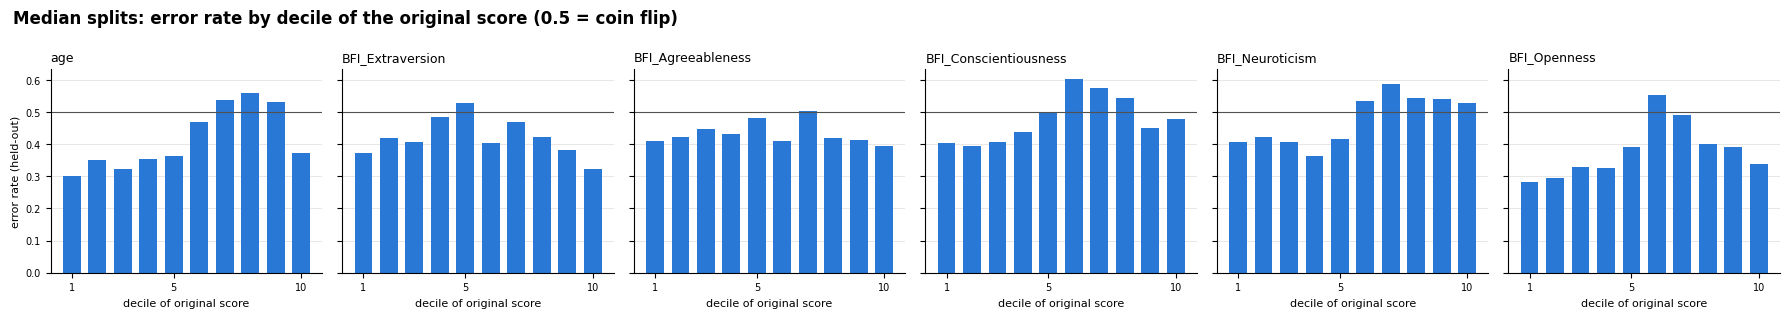

,target,error_outer_deciles,error_middle_deciles,extreme_auc,auc_all
0,age,0.389,0.416,0.638,0.618
1,BFI_Extraversion,0.374,0.466,0.667,0.607
2,BFI_Agreeableness,0.411,0.447,0.618,0.597
3,BFI_Conscientiousness,0.432,0.551,0.565,0.516
4,BFI_Neuroticism,0.475,0.475,0.532,0.530
5,BFI_Openness,0.326,0.473,0.722,0.659


In [25]:
# median-split targets: error rate by decile of the original continuous score
cont = [t for t in targets if KIND[t] == 'continuous']
near_rows = []
fig, axes = plt.subplots(1, len(cont), figsize=(3.0 * len(cont), 3.2), squeeze=False, sharey=True)
for a, name in zip(axes.flat, cont):
    o = OOF[name].copy()
    o['orig'] = ORIG[name].to_numpy(float)[o.row]
    o['decile'] = pd.qcut(o.orig.rank(method='first'), 10, labels=False) + 1
    o['error'] = (o.pred != o.y).astype(float)
    dec = o.groupby('decile').agg(error=('error', 'mean'), lo=('orig', 'min'), hi=('orig', 'max'))
    a.axhline(0.5, color=INK2, lw=0.8)
    a.bar(dec.index, dec.error, color=BLUE, width=0.7)
    a.set_title(name, fontsize=9, loc='left'); a.set_xticks([1, 5, 10]); a.tick_params(labelsize=7)
    a.set_xlabel('decile of original score', fontsize=8); style(a, 'y')
    q1, q3 = o.orig.quantile([0.25, 0.75])
    ext = o[(o.orig <= q1) | (o.orig >= q3)]
    near_rows.append(dict(target=name, error_outer_deciles=dec.error.loc[[1, 2, 9, 10]].mean(),
                          error_middle_deciles=dec.error.loc[[5, 6]].mean(),
                          extreme_auc=roc_auc_score(ext.y, ext.proba) if ext.y.nunique() == 2 else np.nan,
                          auc_all=RES.auc[name]))
axes[0, 0].set_ylabel('error rate (held-out)', fontsize=8)
fig.suptitle('Median splits: error rate by decile of the original score (0.5 = coin flip)', x=0.01, ha='left',
             fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()
near_median = pd.DataFrame(near_rows)
near_median.round(3)

In [26]:
# categorical splits: how often each original answer is predicted as the positive group
sub_rows = []
for name in [t for t in targets if KIND[t] == 'categorical']:
    o = OOF[name].copy()
    o['group'] = ORIG[name].to_numpy()[o.row]
    for g, d in o.groupby('group'):
        sub_rows.append(dict(target=name, group=g, in_positive_class=g in POS_VALUES[name],
                             n=int(len(d) / OUTER_REPEATS), predicted_positive=(d.pred == 1).mean(),
                             mean_proba=d.proba.mean()))
subgroups = pd.DataFrame(sub_rows).sort_values(['target', 'in_positive_class', 'predicted_positive'],
                                               ascending=[True, False, False])
subgroups.round(3)

,target,group,in_positive_class,n,predicted_positive,mean_proba
34,SES,Upper class,True,70,0.690,0.581
35,SES,Upper middle class,True,301,0.596,0.528
33,SES,Middle class,False,228,0.488,0.485
32,SES,Lower middle class,False,123,0.388,0.438
31,SES,At or below poverty line,False,23,0.188,0.331
9,area,Urban,True,358,0.545,0.527
8,area,Suburban,False,380,0.308,0.399
7,area,Rural,False,35,0.152,0.314
0,gender,Female,True,527,0.898,0.804
1,gender,Male,False,239,0.497,0.497


### 9.5 Overfitting and stability
* `optimism` = inner-CV AUC (what tuning saw) − outer AUC (honest). A large gap means selection and tuning fit
  noise in the training folds.
* `fold_sd` = spread of outer AUC across the 15 folds.
* `jaccard` = average overlap of the selected clip sets between folds (1 = identical), next to what two random
  sets of the same sizes would share. Close to the random value → the selected clips are essentially arbitrary.

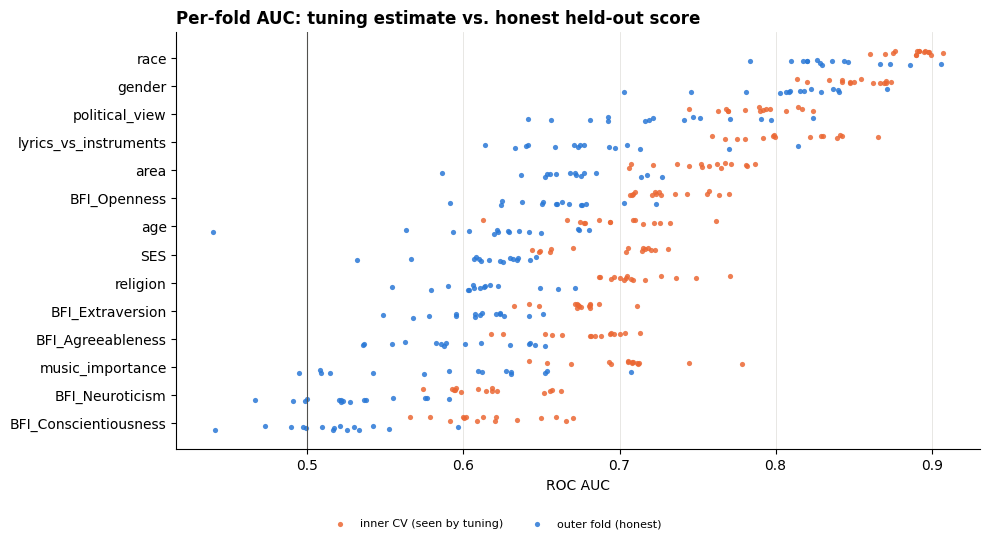

,target,outer_auc,inner_auc,optimism,fold_sd,fold_min,fold_max,clips_median,jaccard,jaccard_random,lr_range,leaves_range,trees_range
0,gender,0.809,0.851,0.042,0.041,0.703,0.871,24.0,0.357,0.037,0.014–0.166,5–63,19–1423
1,race,0.840,0.889,0.049,0.032,0.784,0.906,32.0,0.280,0.067,0.006–0.188,4–55,42–688
2,area,0.670,0.753,0.083,0.035,0.586,0.727,48.0,0.178,0.070,0.007–0.185,5–52,16–1019
3,lyrics_vs_instruments,0.685,0.809,0.124,0.052,0.614,0.814,12.0,0.141,0.023,0.012–0.196,5–47,13–1268
4,music_importance,0.590,0.703,0.113,0.064,0.494,0.708,16.0,0.106,0.055,0.007–0.179,4–54,14–826
5,religion,0.613,0.713,0.099,0.030,0.555,0.671,32.0,0.131,0.050,0.020–0.160,5–64,16–307
6,political_view,0.729,0.788,0.058,0.052,0.641,0.824,24.0,0.196,0.043,0.006–0.148,4–60,26–954
7,SES,0.615,0.691,0.077,0.030,0.532,0.647,64.0,0.176,0.122,0.006–0.193,4–53,37–636
8,age,0.618,0.697,0.079,0.059,0.440,0.680,48.0,0.166,0.092,0.005–0.192,4–61,29–782
9,BFI_Extraversion,0.607,0.672,0.065,0.027,0.548,0.651,32.0,0.129,0.055,0.007–0.170,5–64,14–1113


In [27]:
stab = []
for name, d in fold_results.groupby('target', sort=False):
    masks = np.stack(d.selected_mask.to_numpy()); J, p = masks.shape
    obs, rnd = [], []
    for i in range(J):
        for j in range(i + 1, J):
            a_, b_ = masks[i].sum(), masks[j].sum(); inter = (masks[i] & masks[j]).sum()
            obs.append(inter / (a_ + b_ - inter)); e = a_ * b_ / p; rnd.append(e / (a_ + b_ - e))
    bp = pd.DataFrame(list(d.best_params))
    stab.append(dict(target=name, outer_auc=d.auc.mean(), inner_auc=d.inner_auc.mean(),
                     optimism=(d.inner_auc - d.auc).mean(), fold_sd=d.auc.std(), fold_min=d.auc.min(),
                     fold_max=d.auc.max(), clips_median=d.n_selected.median(),
                     jaccard=np.mean(obs), jaccard_random=np.mean(rnd),
                     lr_range=f"{bp.learning_rate.min():.3f}–{bp.learning_rate.max():.3f}",
                     leaves_range=f"{bp.num_leaves.min()}–{bp.num_leaves.max()}",
                     trees_range=f"{d.n_trees.min()}–{d.n_trees.max()}"))
stab = pd.DataFrame(stab)

fig, a = plt.subplots(figsize=(10, 5.4))
for yi, name in enumerate(order):
    d = fold_results[fold_results.target == name]
    jit = np.random.default_rng(yi).uniform(-0.08, 0.08, len(d))
    a.scatter(d.inner_auc, yi + 0.17 + jit, s=14, color=ORANGE, alpha=0.85, linewidth=0,
              label='inner CV (seen by tuning)' if yi == 0 else None)
    a.scatter(d.auc, yi - 0.17 + jit, s=14, color=BLUE, alpha=0.85, linewidth=0,
              label='outer fold (honest)' if yi == 0 else None)
a.axvline(0.5, color=INK2, lw=0.8)
a.set_yticks(range(len(order))); a.set_yticklabels(order); a.set_xlabel('ROC AUC'); style(a, 'x')
fig.legend(*a.get_legend_handles_labels(), loc='lower center', ncol=2, frameon=False, fontsize=8)
a.set_title('Per-fold AUC: tuning estimate vs. honest held-out score', loc='left', fontweight='bold')
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()
stab.round(3)

In [28]:
# clips selected most consistently across the 15 outer folds (a stable core would show frequencies near 1)
for name, d in fold_results.groupby('target', sort=False):
    freq = np.stack(d.selected_mask.to_numpy()).mean(0)
    top = np.argsort(freq)[::-1][:5]
    print(f"{name:22s} " + " | ".join(f"{freq[i]:.0%} {short(meta.Title.get(FEATURE_NAMES[i], FEATURE_NAMES[i]), 22)}"
                                      for i in top))

gender                 100% "3" | 100% Bootylicious | 100% Bleeding Love | 100% Iron Man | 100% Overworld (Zelda)
race                   100% Guantanamera | 100% Get Busy | 100% Lucy In The Sky With … | 100% Perfect | 100% Hypnotize
area                   100% Texas Tornado | 93% All The Small Things | 80% Lord of the Rings The… | 80% Sugar | 80% Whatcha Say
lyrics_vs_instruments  93% Perfect | 73% Song With Didgeridoo | 67% Kalinka-Malinka | 53% Four Seasons: Concert… | 53% Stay With Me
music_importance       73% Good Life | 67% My Sharona | 67% Nocturne op. 9 no. 2 | 60% Give It To Me | 60% The Girl From Ipanema
religion               93% Love in This Club | 73% Shape of You | 73% Overworld (Zelda) | 73% I'm A Man | 67% Lord of the Rings The…
political_view         100% Footloose | 100% Texas Tornado | 93% Shape of You | 87% Hypnotize | 80% Bootylicious
SES                    93% Guantanamera | 87% Foolish | 87% Shape of You | 80% I Wanna Hold Your Hand | 73% Rock With You
age       

### 9.6 Would more participants help?
Each model is refit on 40–100% of every outer training fold (repeat 1) and scored on the untouched test fold.
To keep this fast, LightGBM here uses the fixed RFE settings on all 320 clips with early stopping (no RFE or
Optuna), next to the Optuna-tuned L2 logistic model from section 8. A curve still rising at 100% means performance is limited by sample size;
a flat curve means more of the same data will not help.

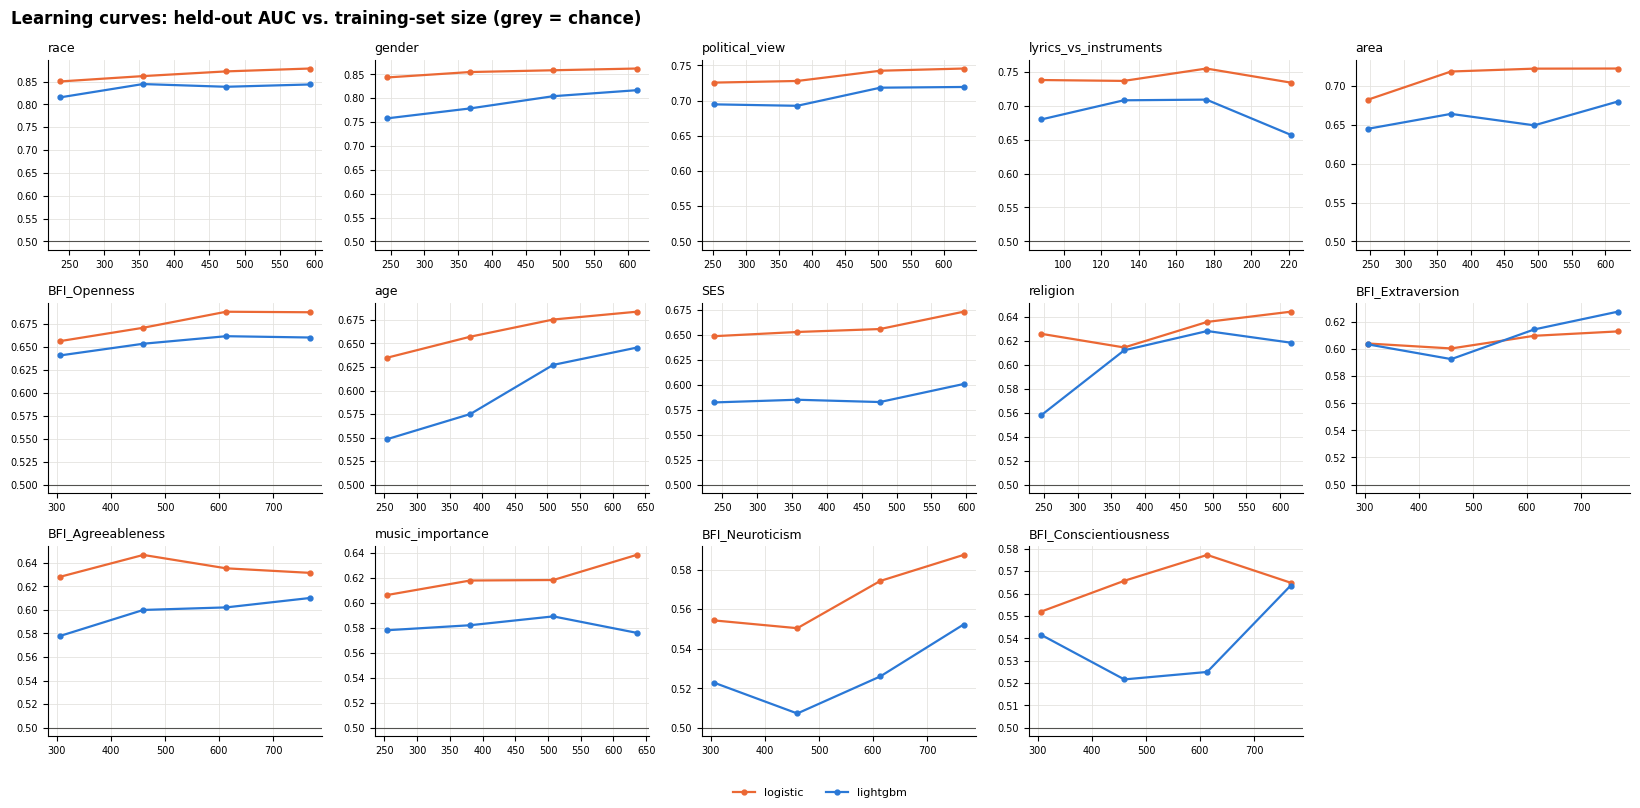

,target,auc_gain_last20pct_logistic,auc_gain_last20pct_lightgbm
0,BFI_Agreeableness,-0.0038,0.0079
1,BFI_Conscientiousness,-0.0124,0.0385
2,BFI_Extraversion,0.0032,0.0131
3,BFI_Neuroticism,0.0132,0.0263
4,BFI_Openness,-0.0006,-0.0014
5,SES,0.0174,0.0181
6,age,0.0083,0.0184
7,area,0.0001,0.0306
8,gender,0.0036,0.0125
9,lyrics_vs_instruments,-0.0207,-0.0518


In [29]:
FRACS = [0.4, 0.6, 0.8, 1.0]


def lc_job(name, fold_id, tr, te, frac, model):
    warnings.filterwarnings('ignore')
    Xn, yn = DATA[name]; seed = SEED + fold_id
    if frac < 1:
        tr, _ = train_test_split(tr, train_size=frac, random_state=seed, stratify=yn[tr])
    if model == 'logistic':
        p = fit_logit('L2', Xn[tr], yn[tr], seed)[0].predict_proba(Xn[te])[:, 1]
    else:
        a, b = train_test_split(tr, test_size=ES_HOLDOUT, random_state=seed, stratify=yn[tr])
        p = fit_es(RFE_PARAMS, seed, Xn[a], yn[a], Xn[b], yn[b]).predict_proba(Xn[te])[:, 1]
    return dict(target=name, frac=frac, n_train=len(tr), model=model, auc=roc_auc_score(yn[te], p))


lc_jobs = [(name, i, tr, te, f, m) for name in targets for i, (tr, te) in enumerate(FOLDS[name][:OUTER_SPLITS])
           for f in FRACS for m in ('logistic', 'lightgbm')]
lc = (pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(lc_job)(*j) for j in lc_jobs))
        .groupby(['target', 'model', 'frac'], sort=False).agg(n_train=('n_train', 'mean'), auc=('auc', 'mean'))
        .reset_index())

ncol = 5; nrow = int(np.ceil(len(targets) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.3 * ncol, 2.7 * nrow), squeeze=False)
for a, name in zip(axes.flat, order[::-1]):
    for model, color in [('logistic', ORANGE), ('lightgbm', BLUE)]:
        g = lc[(lc.target == name) & (lc.model == model)]
        a.plot(g.n_train, g.auc, '-o', color=color, ms=3.5, lw=1.6, label=model)
    a.axhline(0.5, color=INK2, lw=0.8)
    a.set_title(name, fontsize=9, loc='left'); a.tick_params(labelsize=7); style(a)
for a in list(axes.flat)[len(targets):]:
    a.axis('off')
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='lower center', ncol=2, frameon=False, fontsize=8)
fig.suptitle('Learning curves: held-out AUC vs. training-set size (grey = chance)', x=0.01, ha='left',
             fontsize=12, fontweight='bold')
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

lc_gain = (lc.pivot_table(index='target', columns=['model', 'frac'], values='auc')
             .pipe(lambda t: pd.DataFrame({m: t[(m, 1.0)] - t[(m, 0.8)] for m in ('logistic', 'lightgbm')}))
             .add_prefix('auc_gain_last20pct_').reset_index())
lc_gain.round(4)

### 9.7 Summary
One row per target, left to right: performance, whether a linear model or the continuous score does better,
how much single-clip signal exists, which side of the split fails, calibration / threshold, overfitting and
selection stability, and whether more data would help.

In [30]:
summary = (results[['target', 'rule', 'positive_class', 'share_positive', 'auc', 'bal_acc']]
           .merge(baseline[['target', 'logistic_auc', 'lgbm_minus_logistic_auc', 'p_corrected']
                           + (['ridge_continuous_auc'] if 'ridge_continuous_auc' in baseline else [])], on='target')
           .merge(signal[['target', 'best_over_null', 'clips_q05', 'reliability_alpha']], on='target')
           .merge(per_target[['target', 'sensitivity', 'specificity']], on='target')
           .merge(calib[['target', 'brier_skill', 'threshold_gain']], on='target')
           .merge(near_median[['target', 'error_outer_deciles', 'error_middle_deciles', 'extreme_auc']], on='target', how='left')
           .merge(stab[['target', 'optimism', 'fold_sd', 'jaccard', 'jaccard_random']], on='target')
           .merge(lc_gain, on='target', how='left'))
summary.to_csv("../results/music_binary/music_binary_diagnostics.csv", index=False)
subgroups.to_csv("../results/music_binary/music_binary_subgroups.csv", index=False)
print("saved music_binary_diagnostics.csv and music_binary_subgroups.csv")
summary.round(3)

saved music_binary_diagnostics.csv and music_binary_subgroups.csv


,target,rule,positive_class,share_positive,auc,bal_acc,logistic_auc,lgbm_minus_logistic_auc,p_corrected,ridge_continuous_auc,...,threshold_gain,error_outer_deciles,error_middle_deciles,extreme_auc,optimism,fold_sd,jaccard,jaccard_random,auc_gain_last20pct_logistic,auc_gain_last20pct_lightgbm
0,gender,grouped answers,Female,0.688,0.809,0.700,0.859,-0.050,0.031,NaN,...,0.036,NaN,NaN,NaN,0.042,0.041,0.357,0.037,0.004,0.013
1,race,grouped answers (dropped 53),Asian,0.430,0.840,0.770,0.875,-0.036,0.027,NaN,...,0.001,NaN,NaN,NaN,0.049,0.032,0.280,0.067,0.006,0.005
2,area,grouped answers,Urban,0.463,0.670,0.625,0.735,-0.064,0.007,NaN,...,0.004,NaN,NaN,NaN,0.083,0.035,0.178,0.070,0.000,0.031
3,lyrics_vs_instruments,grouped answers (dropped 513),Lyrics,0.500,0.685,0.648,0.758,-0.073,0.017,NaN,...,0.007,NaN,NaN,NaN,0.124,0.052,0.141,0.023,-0.021,-0.052
4,music_importance,grouped answers,big role / music is my life,0.807,0.590,0.510,0.629,-0.039,0.329,NaN,...,0.065,NaN,NaN,NaN,0.113,0.064,0.106,0.055,0.020,-0.013
5,religion,grouped answers,Atheist / agnostic,0.412,0.613,0.577,0.648,-0.034,0.120,NaN,...,0.009,NaN,NaN,NaN,0.099,0.030,0.131,0.050,0.008,-0.010
6,political_view,grouped answers,left (liberal / progressive / socialist),0.635,0.729,0.654,0.744,-0.015,0.448,NaN,...,0.033,NaN,NaN,NaN,0.058,0.052,0.196,0.043,0.003,0.001
7,SES,grouped answers,upper / upper middle class,0.498,0.615,0.588,0.676,-0.061,0.002,NaN,...,0.005,NaN,NaN,NaN,0.077,0.030,0.176,0.122,0.017,0.018
8,age,median split at 19,high (> 19),0.467,0.618,0.578,0.673,-0.054,0.110,0.635,...,0.005,0.389,0.416,0.638,0.079,0.059,0.166,0.092,0.008,0.018
9,BFI_Extraversion,median split at 3.125,high (≥ 3.125),0.515,0.607,0.578,0.614,-0.007,0.680,0.616,...,0.005,0.374,0.466,0.667,0.065,0.027,0.129,0.055,0.003,0.013


## 10. Accuracy summary for selected targets
Held-out accuracy of the best model per target (highest accuracy in section 8.3). **Numbers are hardcoded** from the
section 8.3 output of the 2026-10-04 run without class weighting, so this cell runs on its own; update `ACC` if the notebook is rerun with
different settings. For reference, `ACC.baseline` holds the accuracy of always guessing the larger group (not plotted).

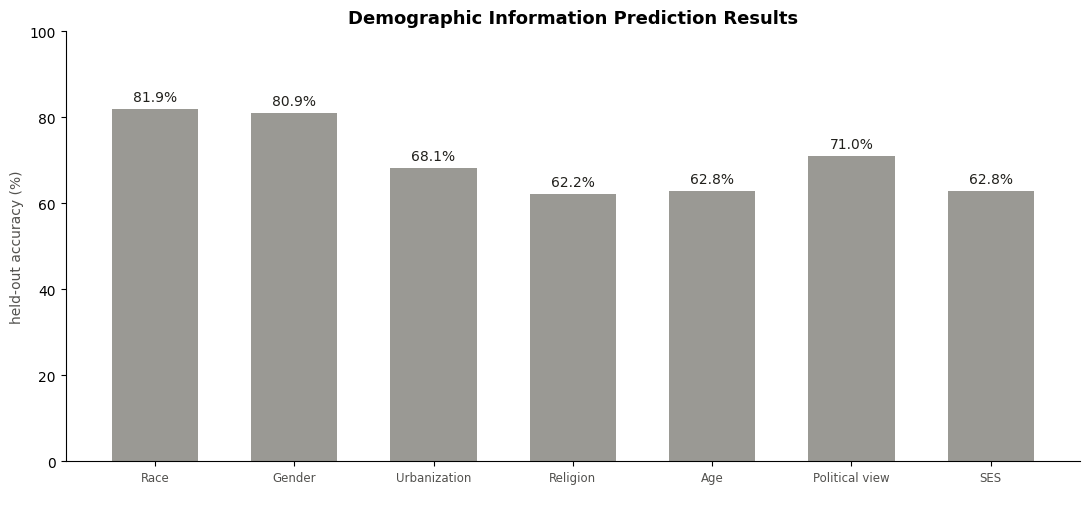

In [4]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# held-out accuracy of the best model per target (section 8.3 table, unweighted run of 2026-10-04, 22:39);
# baseline = accuracy of always guessing the larger group (kept for reference, not plotted)
ACC = pd.DataFrame([
    ('Race', '', 'logistic L2', 0.819, 0.570),
    ('Gender', '', 'logistic L2', 0.809, 0.688),
    ('Urbanization', '', 'logistic L2', 0.681, 0.537),
    ('Religion', '', 'logistic L2', 0.622, 0.588),
    ('Age', '', 'logistic L2', 0.628, 0.533),
    ('Political view', '', 'logistic L2', 0.710, 0.635),
    ('SES', '', 'logistic L2', 0.628, 0.502),
], columns=['target', 'split', 'model', 'accuracy', 'baseline'])

BAR, INK, INK2 = '#9a9994', '#21201c', '#52514e'
x = np.arange(len(ACC))
fig, a = plt.subplots(figsize=(11, 5.2))
a.bar(x, 100 * ACC.accuracy, width=0.62, color=BAR)
for xi, acc in zip(x, ACC.accuracy):
    a.text(xi, 100 * acc + 1.2, f"{100 * acc:.1f}%", ha='center', va='bottom', fontsize=10, color=INK)
a.set_xticks(x)
a.set_xticklabels([f"{t}\n{s}" for t, s in zip(ACC.target, ACC.split)], fontsize=8.5, color=INK2)
a.set_ylim(0, 100); a.set_ylabel('held-out accuracy (%)', color=INK2)
a.spines[['top', 'right']].set_visible(False)
a.set_title('Demographic Information Prediction Results', loc='center', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("../results/music_binary/music_binary_accuracy.png", dpi=300)
plt.show()